<a href="https://colab.research.google.com/github/RAHUL423-BIOMEDICAL/biomedical-research-portfolio/blob/main/00_setup_and_data_download.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# 1. Connect your Google Drive to Colab
from google.colab import drive
drive.mount('/content/drive')

# 2. Create our clean publication folder structure inside your Google Drive
import os

base_dir = "/content/drive/MyDrive/pd-smartwatch-domain-shift"
folders = [
    "data/raw/pads",
    "data/raw/bioclite",
    "data/processed",
    "data/metadata",
    "src",
    "results/tables",
    "results/figures",
    "manuscript/sections",
    "models"
]

for f in folders:
    os.makedirs(os.path.join(base_dir, f), exist_ok=True)

print("✅ Lab bench created successfully at:", base_dir)

Mounted at /content/drive
✅ Lab bench created successfully at: /content/drive/MyDrive/pd-smartwatch-domain-shift


In [ ]:
import os, subprocess

base_dir = "/content/drive/MyDrive/pd-smartwatch-domain-shift"
pads_dir = os.path.join(base_dir, "data/raw/pads")
bio_dir = os.path.join(base_dir, "data/raw/bioclite")

# 1. Download BIOCLITE files from Zenodo (Record 16408199)
print("⬇️ Downloading BIOCLITE from Zenodo...")
!wget -c -P "$bio_dir" "https://zenodo.org/records/16408199/files/BBDD_BIOCLITE_v0.mat"
!wget -c -P "$bio_dir" "https://zenodo.org/records/16408199/files/Bioclite_README.txt"

# 2. Mirror PADS v1.0.0 from PhysioNet into data/raw/pads
print("⬇️ Downloading PADS v1.0.0 from PhysioNet (this may take a few minutes)...")
!wget -r -N -c -np -nH --cut-dirs=3 -P "$pads_dir" "https://physionet.org/files/parkinsons-disease-smartwatch/1.0.0/"

print("\n--- BIOCLITE Files ---")
!ls -lh "$bio_dir"

print("\n--- PADS Top-Level Folders ---")
!ls -la "$pads_dir"

Streaming output truncated to the last 5000 lines.
Connecting to physionet-open.s3.amazonaws.com (physionet-open.s3.amazonaws.com)|52.216.213.82|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 96555 (94K) [binary/octet-stream]
Saving to: ‘/content/drive/MyDrive/pd-smartwatch-domain-shift/data/raw/pads/movement/timeseries/194_TouchIndex_RightWrist.txt’

movement/timeseries 100%[===================>]  94.29K  --.-KB/s    in 0.1s    

2026-11-19 21:40:20 (759 KB/s) - ‘/content/drive/MyDrive/pd-smartwatch-domain-shift/data/raw/pads/movement/timeseries/194_TouchIndex_RightWrist.txt’ saved [96555/96555]

--2026-11-19 21:40:20--  https://physionet.org/files/parkinsons-disease-smartwatch/1.0.0/movement/timeseries/194_TouchNose_LeftWrist.txt
Connecting to physionet.org (physionet.org)|18.25.8.254|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://physionet-open.s3.amazonaws.com/parkinsons-disease-smartwatch/1.0.0/movement/timeseries/

In [1]:
from google.colab import drive
import os, glob

drive.mount('/content/drive', force_remount=False)

base_dir = "/content/drive/MyDrive/pd-smartwatch-domain-shift"
pads_dir = os.path.join(base_dir, "data/raw/pads")
bio_dir = os.path.join(base_dir, "data/raw/bioclite")

print("=== 1. BIOCLITE status ===")
!ls -lh "$bio_dir"

print("\n=== 2. PADS status ===")
!ls -la "$pads_dir"
ts_files = glob.glob(os.path.join(pads_dir, "**/*Wrist.txt"), recursive=True)
print("Total PADS *Wrist.txt files already in Drive:", len(ts_files))

print("\n=== 3. Resuming any remaining downloads (-c) ===")
!wget -c -P "$bio_dir" "https://zenodo.org/records/16408199/files/BBDD_BIOCLITE_v0.mat"
!wget -c -P "$bio_dir" "https://zenodo.org/records/16408199/files/Bioclite_README.txt"
!wget -r -N -c -np -nH --cut-dirs=3 -P "$pads_dir" "https://physionet.org/files/parkinsons-disease-smartwatch/1.0.0/"

Streaming output truncated to the last 5000 lines.
Connecting to physionet.org (physionet.org)|18.25.8.254|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://physionet-open.s3.amazonaws.com/parkinsons-disease-smartwatch/1.0.0/preprocessed/questionnaire/118_ml.bin [following]
--2026-11-20 06:15:38--  https://physionet-open.s3.amazonaws.com/parkinsons-disease-smartwatch/1.0.0/preprocessed/questionnaire/118_ml.bin
Connecting to physionet-open.s3.amazonaws.com (physionet-open.s3.amazonaws.com)|16.15.207.4|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 120 [binary/octet-stream]
Saving to: ‘/content/drive/MyDrive/pd-smartwatch-domain-shift/data/raw/pads/preprocessed/questionnaire/118_ml.bin’

preprocessed/questi 100%[===================>]     120  --.-KB/s    in 0s      

2026-11-20 06:15:38 (1.26 MB/s) - ‘/content/drive/MyDrive/pd-smartwatch-domain-shift/data/raw/pads/preprocessed/questionnaire/118_ml.bin’ saved [120/120]

--202

In [2]:
import os, glob, json
import pandas as pd
import scipy.io as sio

base_dir = "/content/drive/MyDrive/pd-smartwatch-domain-shift"
pads_dir = os.path.join(base_dir, "data/raw/pads")
bio_dir = os.path.join(base_dir, "data/raw/bioclite")

print("All files in PADS folder:")
for p in sorted(glob.glob(os.path.join(pads_dir, "**/*"), recursive=True)):
    if os.path.isfile(p) and not p.endswith(".txt"):
        print(" ", os.path.relpath(p, pads_dir))

ts_files = sorted(glob.glob(os.path.join(pads_dir, "**/*Wrist.txt"), recursive=True))
print(f"\nTotal timeseries files: {len(ts_files)}")
if ts_files:
    print("Sample timeseries file:", ts_files[0])
    print(pd.read_csv(ts_files[0]).head(3))

readme_path = os.path.join(bio_dir, "Bioclite_README.txt")
if os.path.exists(readme_path):
    print("\n--- Bioclite_README.txt ---")
    with open(readme_path) as f:
        print(f.read()[:1500])

mat_path = os.path.join(bio_dir, "BBDD_BIOCLITE_v0.mat")
if os.path.exists(mat_path):
    try:
        mat_data = sio.loadmat(mat_path, squeeze_me=True, struct_as_record=False)
        print("\nBIOCLITE .mat keys:", [k for k in mat_data.keys() if not k.startswith("__")])
    except Exception as e:
        print("\nBIOCLITE .mat load note:", e)

All files in PADS folder:
  index.html
  movement/index.html
  movement/observation_001.json
  movement/observation_002.json
  movement/observation_003.json
  movement/observation_004.json
  movement/observation_005.json
  movement/observation_006.json
  movement/observation_007.json
  movement/observation_008.json
  movement/observation_009.json
  movement/observation_010.json
  movement/observation_011.json
  movement/observation_012.json
  movement/observation_013.json
  movement/observation_014.json
  movement/observation_015.json
  movement/observation_016.json
  movement/observation_017.json
  movement/observation_018.json
  movement/observation_019.json
  movement/observation_020.json
  movement/observation_021.json
  movement/observation_022.json
  movement/observation_023.json
  movement/observation_024.json
  movement/observation_025.json
  movement/observation_026.json
  movement/observation_027.json
  movement/observation_028.json
  movement/observation_029.json
  movement/

In [4]:
import os, glob, json
import pandas as pd
import scipy.io as sio

base_dir = "/content/drive/MyDrive/pd-smartwatch-domain-shift"
pads_dir = os.path.join(base_dir, "data/raw/pads")
bio_dir = os.path.join(base_dir, "data/raw/bioclite")

# 1. Read full Bioclite_README.txt
print("=== 1. FULL BIOCLITE README ===")
with open(os.path.join(bio_dir, "Bioclite_README.txt")) as f:
    print(f.read())

# 2. Load BBDD_BIOCLITE_v0.mat using scipy.io.loadmat
print("\n=== 2. BIOCLITE .MAT STRUCTURE ===")
mat_path = os.path.join(bio_dir, "BBDD_BIOCLITE_v0.mat")
try:
    # loadmat handles older MAT files (v5/v7).
    # struct_as_record=False and squeeze_me=True help parse structures cleanly.
    bio_mat = sio.loadmat(mat_path, struct_as_record=False, squeeze_me=True)
    print("Keys found:", [k for k in bio_mat.keys() if not k.startswith("__")])

    # Display detailed info of non-private keys
    for k, v in bio_mat.items():
        if not k.startswith("__"):
            print(f"Key: {k} | Type: {type(v)}")
except Exception as e:
    print("Error loading with scipy.io.loadmat:", e)

# 3. Inspect PADS metadata & timeseries files
print("\n=== 3. PADS METADATA & FILES ===")
non_txt = [os.path.relpath(p, pads_dir) for p in sorted(glob.glob(os.path.join(pads_dir, "**/*"), recursive=True)) if os.path.isfile(p) and not p.endswith(".txt")]
print("Non-txt files count:", len(non_txt))
print("Sample non-txt files:", non_txt[:10])

ts_files = sorted(glob.glob(os.path.join(pads_dir, "**/*Wrist.txt"), recursive=True))
print("Total PADS *Wrist.txt files:", len(ts_files))
if ts_files:
    print("Sample file:", os.path.basename(ts_files[0]))
    with open(ts_files[0]) as f:
        for _ in range(5):
            print("  ", f.readline().strip())

=== 1. FULL BIOCLITE README ===
BIOCLITE: Smartwatch Dataset for Parkinson's Disease in Supervised and Unsupervised Contexts

BIOCLITE DATABASE v1.0

The dataset collected during the experimental campaign consists of triaxial acceleration and triaxial gyroscope data recorded from a smartwatch, gathered from 24 patients with Parkinson’s disease and 16 healthy participants. Data was recorded at a sampling rate of 50 Hz and expressed in m/s² and rad/s.

Each participant performed 8 different exercises in both supervised and unsupervised contexts. The complete set of exercises was performed once per day, typically at a consistent time. Each participant began with an initial supervised session, followed by seven consecutive days of unsupervised sessions, and concluded with a final supervised session.

The data is structured in a table format where each row represents all the data related to one day or trial session. The column organization is as follows:
•	Column 1: Participant group — with

In [6]:
import os, glob, json
import scipy.io as sio
import numpy as np

base_dir = "/content/drive/MyDrive/pd-smartwatch-domain-shift"
pads_dir = os.path.join(base_dir, "data/raw/pads")
bio_dir = os.path.join(base_dir, "data/raw/bioclite")

# 1. Inspect PADS JSON schema (patient & observation)
p_jsons = sorted(glob.glob(os.path.join(pads_dir, "**/*patient*.json"), recursive=True))
o_jsons = sorted(glob.glob(os.path.join(pads_dir, "**/*observation*.json"), recursive=True))
print(f"PADS patient JSONs: {len(p_jsons)} | observation JSONs: {len(o_jsons)}")

if p_jsons:
    with open(p_jsons[0]) as f:
        print("Sample patient JSON:", json.dumps(json.load(f), indent=2))
if o_jsons:
    with open(o_jsons[0]) as f:
        od = json.load(f)
        print("Sample observation JSON keys:", list(od.keys()))
        print("Sample session[0]:", json.dumps(od["session"][0], indent=2))

# 2. Inspect BIOCLITE MAT using scipy.io.loadmat (compatible with MATLAB v5.0 files)
mat_path = os.path.join(bio_dir, "BBDD_BIOCLITE_v0.mat")
print("\n=== Reading BIOCLITE with scipy.io.loadmat ===")
try:
    # loadmat loads older MATLAB format files safely
    mat_data = sio.loadmat(mat_path, struct_as_record=False, squeeze_me=True)
    print("Keys in file:", [k for k in mat_data.keys() if not k.startswith("__")])
    for k, v in mat_data.items():
        if not k.startswith("__"):
            print(f"Key: '{k}', Type: {type(v)}")
except Exception as e:
    print("Error loading with scipy.io.loadmat:", e)

PADS patient JSONs: 469 | observation JSONs: 469
Sample patient JSON: {
  "resource_type": "patient",
  "id": "001",
  "study_id": "PADS",
  "condition": "Healthy",
  "disease_comment": "-",
  "age_at_diagnosis": 56,
  "age": 56,
  "height": 173,
  "weight": 78,
  "gender": "male",
  "handedness": "right",
  "appearance_in_kinship": true,
  "appearance_in_first_grade_kinship": true,
  "effect_of_alcohol_on_tremor": "Unknown"
}
Sample observation JSON keys: ['resource_type', 'subject_id', 'study_id', 'device_id', 'id', 'endianness', 'sampling_rate', 'data_type', 'bits', 'session']
Sample session[0]: {
  "record_name": "Relaxed",
  "rows": 2048,
  "records": [
    {
      "device_location": "LeftWrist",
      "channels": [
        "Time",
        "Accelerometer_X",
        "Accelerometer_Y",
        "Accelerometer_Z",
        "Gyroscope_X",
        "Gyroscope_Y",
        "Gyroscope_Z"
      ],
      "units": [
        "s",
        "g",
        "g",
        "g",
        "rad/s",
        "

In [7]:
import os, glob, json
import pandas as pd
import scipy.io as sio

base_dir = "/content/drive/MyDrive/pd-smartwatch-domain-shift"
pads_dir = os.path.join(base_dir, "data/raw/pads")
bio_dir = os.path.join(base_dir, "data/raw/bioclite")

# 1. Parse all 469 PADS patient JSONs and verify condition counts
p_jsons = sorted(glob.glob(os.path.join(pads_dir, "**/*patient*.json"), recursive=True))
patients = [json.load(open(p)) for p in p_jsons]
df_pads_meta = pd.DataFrame(patients)

print("=== PADS CONDITION COUNTS (Total N = 469) ===")
print(df_pads_meta["condition"].value_counts(dropna=False))
df_pads_meta.to_csv(os.path.join(base_dir, "data/metadata/pads_demographics.csv"), index=False)

# 2. Check how BIOCLITE .mat is formatted (MATLAB v5 MCOS vs HDF5)
mat_path = os.path.join(bio_dir, "BBDD_BIOCLITE_v0.mat")
with open(mat_path, "rb") as f:
    header = f.read(128)
print("\n=== BIOCLITE .MAT HEADER ===")
print(header[:80])

# Inspect MatlabOpaque object inside scipy.io.loadmat
mat_raw = sio.loadmat(mat_path, squeeze_me=False)
for k, v in mat_raw.items():
    if not k.startswith("__"):
        print("Key:", repr(k), "Type:", type(v), "Shape:", getattr(v, "shape", None))

=== PADS CONDITION COUNTS (Total N = 469) ===
condition
Parkinson's                 276
Healthy                      79
Other Movement Disorders     60
Essential Tremor             28
Atypical Parkinsonism        15
Multiple Sclerosis           11
Name: count, dtype: int64

=== BIOCLITE .MAT HEADER ===
b'MATLAB 5.0 MAT-file, Platform: PCWIN64, Created on: Thu Jul 31 08:58:42 2025    '
Key: 'None' Type: <class 'scipy.io.matlab._mio5_params.MatlabOpaque'> Shape: (1,)


In [8]:
import os
import pandas as pd
import numpy as np

base_dir = "/content/drive/MyDrive/pd-smartwatch-domain-shift"
bio_dir = os.path.join(base_dir, "data/raw/bioclite")
meta_dir = os.path.join(base_dir, "data/metadata")
tables_dir = os.path.join(base_dir, "results/tables")

# 1. Generate Table 1 (PADS Cohort Demographics) right now!
df_pads = pd.read_csv(os.path.join(meta_dir, "pads_demographics.csv"))
df_pads["disease_duration"] = df_pads["age"] - df_pads["age_at_diagnosis"]

def summarize_group(sub, name):
    n = len(sub)
    age_str = f"{sub['age'].mean():.1f} ± {sub['age'].std():.1f}"
    male_n = (sub["gender"].str.lower() == "male").sum()
    male_str = f"{male_n} ({100*male_n/n:.1f}%)"
    right_n = (sub["handedness"].str.lower() == "right").sum()
    right_str = f"{right_n} ({100*right_n/n:.1f}%)"
    if name == "PD":
        dur_str = f"{sub['disease_duration'].mean():.1f} ± {sub['disease_duration'].std():.1f}"
    else:
        dur_str = "—"
    return {"Group": name, "N": n, "Age (years)": age_str, "Male, n (%)": male_str,
            "Right-handed, n (%)": right_str, "Disease Duration (years)": dur_str}

table1_rows = [
    summarize_group(df_pads[df_pads["condition"] == "Parkinson's"], "PD"),
    summarize_group(df_pads[df_pads["condition"] == "Healthy"], "HC"),
    summarize_group(df_pads[~df_pads["condition"].isin(["Parkinson's", "Healthy"])], "DD (Other)")
]
df_table1 = pd.DataFrame(table1_rows)
df_table1.to_csv(os.path.join(tables_dir, "table1_pads_demographics.csv"), index=False)
print("=== TABLE 1: PADS COHORT DEMOGRAPHICS ===")
print(df_table1.to_string(index=False))

# 2. Install Octave (takes ~15s) to inspect & export BIOCLITE MATLAB table cleanly
!apt-get -qq update && apt-get -qq install -y octave

=== TABLE 1: PADS COHORT DEMOGRAPHICS ===
     Group   N Age (years) Male, n (%) Right-handed, n (%) Disease Duration (years)
        PD 276  65.4 ± 9.6 195 (70.7%)         261 (94.6%)               8.8 ± 10.6
        HC  79 62.9 ± 12.5  29 (36.7%)          70 (88.6%)                        —
DD (Other) 114 62.4 ± 11.5  57 (50.0%)         106 (93.0%)                        —
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Extracting templates from packages: 100%
Selecting previously unselected package fonts-droid-fallback.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../fonts-droid-fallback_1%3a6.0.1r16-1.1build1_all.deb ...
Unpacking fonts-droid-fallback (1:6.0.1r16-1.1build1) ...
Selecting previously unselected package poppler-data.
Preparing to unpack .../poppler-data_0.4.12-1_all.deb ...
Unpacki

In [9]:
import subprocess, os

base_dir = "/content/drive/MyDrive/pd-smartwatch-domain-shift"
mat_path = os.path.join(base_dir, "data/raw/bioclite/BBDD_BIOCLITE_v0.mat")

octave_check = f"""
warning('off', 'all');
S = load('{mat_path}');
fn = fieldnames(S);
disp('Fieldnames:'); disp(fn);
for i = 1:length(fn)
    val = S.(fn{{i}});
    disp(['Class of ', fn{{i}}, ': ', class(val), ' | Size: ', num2str(size(val))]);
end
"""

with open("/tmp/check_bio.m", "w") as f:
    f.write(octave_check)

!octave --no-gui --quiet /tmp/check_bio.m

Fieldnames:
{
  [1,1] = BBDD_BIOCLITE_v0
}
Class of BBDD_BIOCLITE_v0: struct | Size: 1  1


In [10]:
import os

base_dir = "/content/drive/MyDrive/pd-smartwatch-domain-shift"
mat_path = os.path.join(base_dir, "data/raw/bioclite/BBDD_BIOCLITE_v0.mat")

octave_inspect = f"""
warning('off', 'all');
S = load('{mat_path}');
T = S.BBDD_BIOCLITE_v0;
disp('Subfields of BBDD_BIOCLITE_v0:');
disp(fieldnames(T));
fn = fieldnames(T);
for i = 1:length(fn)
    val = T.(fn{{i}});
    disp(['Field ', fn{{i}}, ' -> class: ', class(val), ' | size: ', num2str(size(val))]);
end
"""

with open("/tmp/inspect_bio_struct.m", "w") as f:
    f.write(octave_inspect)

!octave --no-gui --quiet /tmp/inspect_bio_struct.m

Subfields of BBDD_BIOCLITE_v0:
{
  [1,1] = MCOS
  [2,1] = table
}
Field MCOS -> class: uint32 | size: 6  1
error: structure has no member 'table'
error: called from
    /tmp/inspect_bio_struct.m at line 9 column 9


In [16]:
import os

base_dir = "/content/drive/MyDrive/pd-smartwatch-domain-shift"
mat_path = os.path.join(base_dir, "data/raw/bioclite/BBDD_BIOCLITE_v0.mat")

# Writing a clean script without using string replacements to avoid template corruption
octave_probe = """
warning('off', 'all');
S = load('/content/drive/MyDrive/pd-smartwatch-domain-shift/data/raw/bioclite/BBDD_BIOCLITE_v0.mat');
T = S.BBDD_BIOCLITE_v0;

disp('=== 1. Inspecting BBDD_BIOCLITE_v0 fields ===');
if isstruct(T)
    fields = fieldnames(T);
    for i = 1:length(fields)
        fn = fields{i};
        val = T.(fn);
        fprintf('Field name: %s | class: %s | size: %s\\n', fn, class(val), num2str(size(val)));
    end
else
    fprintf('BBDD_BIOCLITE_v0 is a: %s\\n', class(T));
end
"""

with open("/tmp/probe_bio.m", "w") as f:
    f.write(octave_probe)

!octave --no-gui --quiet /tmp/probe_bio.m

=== 1. Inspecting BBDD_BIOCLITE_v0 fields ===
Field name: MCOS | class: uint32 | size: 6  1
error: structure has no member 'table'
error: called from
    /tmp/probe_bio.m at line 11 column 13


In [17]:
import os, io
import scipy.io as sio
from scipy.io.matlab._mio5 import MatFile5Reader

base_dir = "/content/drive/MyDrive/pd-smartwatch-domain-shift"
mat_path = os.path.join(base_dir, "data/raw/bioclite/BBDD_BIOCLITE_v0.mat")

raw = sio.loadmat(mat_path, squeeze_me=False)
fw = raw["__function_workspace__"]

buf = io.BytesIO(fw.tobytes())
buf.read(128)  # skip internal 128-byte sub-header

reader = MatFile5Reader(buf, squeeze_me=True, struct_as_record=False)
vars_inside = reader.get_variables()

print("Keys inside MCOS workspace:", list(vars_inside.keys()))
for k, v in vars_inside.items():
    print(f"  {k}: type={type(v)}, shape={getattr(v, 'shape', len(v) if hasattr(v, '__len__') else 'N/A')}")

TypeError: Expecting miMATRIX type here, got 1181314149

In [18]:
import os, struct
import numpy as np

base_dir = "/content/drive/MyDrive/pd-smartwatch-domain-shift"
mat_path = os.path.join(base_dir, "data/raw/bioclite/BBDD_BIOCLITE_v0.mat")

with open(mat_path, "rb") as f:
    data = f.read()

print("BIOCLITE file size (MB):", round(len(data) / (1024 * 1024), 2))
# Scan for MATLAB miDOUBLE data element tag (dtype = 9, little-endian)
# In MAT v5, miDOUBLE is tag: uint32(9), uint32(nbytes)
pos = 128
double_blocks = []
while pos < len(data) - 8:
    dtype, nbytes = struct.unpack_from("<II", data, pos)
    if dtype == 9 and 24 <= nbytes <= 50_000_000 and nbytes % 8 == 0:
        count = nbytes // 8
        arr = np.frombuffer(data, dtype="<f8", count=count, offset=pos + 8)
        if np.all(np.isfinite(arr)) and np.max(np.abs(arr)) < 1e6:
            double_blocks.append((pos, count, float(np.min(arr)), float(np.max(arr))))
        pos += 8 + ((nbytes + 7) & ~7)
    else:
        pos += 4

print(f"Found {len(double_blocks)} clean float64 blocks.")
for b in double_blocks[:10]:
    print(f"  offset={b[0]}, n_doubles={b[1]}, min={b[2]:.3f}, max={b[3]:.3f}")

BIOCLITE file size (MB): 53.56
Found 0 clean float64 blocks.


In [19]:
import os, struct, zlib
import numpy as np

base_dir = "/content/drive/MyDrive/pd-smartwatch-domain-shift"
mat_path = os.path.join(base_dir, "data/raw/bioclite/BBDD_BIOCLITE_v0.mat")

with open(mat_path, "rb") as f:
    data = f.read()

pos = 128
streams = []
while pos < len(data) - 8:
    dtype, nbytes = struct.unpack_from("<II", data, pos)
    if dtype == 15:  # miCOMPRESSED (zlib)
        raw_chunk = zlib.decompress(data[pos + 8 : pos + 8 + nbytes])
        streams.append(raw_chunk)
        pos += 8 + ((nbytes + 7) & ~7)
    else:
        pos += 8 + ((nbytes + 7) & ~7)

print(f"Decompressed {len(streams)} zlib stream(s).")
for idx, s in enumerate(streams):
    print(f"  Stream {idx}: {len(s)/(1024*1024):.2f} MB | header bytes: {s[:40]}")

Decompressed 1 zlib stream(s).
  Stream 0: 0.00 MB | header bytes: b'\x0e\x00\x00\x00\x90\x00\x00\x00\x06\x00\x00\x00\x08\x00\x00\x00\x11\x00\x00\x00\x00\x00\x00\x00\x01\x00\x00\x00\x10\x00\x00\x00BBDD_BIO'


import os, zlib, re
import numpy as np

base_dir = "/content/drive/MyDrive/pd-smartwatch-domain-shift"
mat_path = os.path.join(base_dir, "data/raw/bioclite/BBDD_BIOCLITE_v0.mat")

with open(mat_path, "rb") as f:
    data = f.read()

# Find all valid zlib streams (0x78 0x9c = default compression, 0x78 0xda = best compression)
decompressed_blobs = []
for sig in [b"\x78\x9c", b"\x78\xda", b"\x78\x01"]:
    idx = 128
    while True:
        idx = data.find(sig, idx)
        if idx == -1:
            break
        try:
            dobj = zlib.decompressobj()
            out = dobj.decompress(data[idx:])
            if len(out) > 1000:
                decompressed_blobs.append((idx, len(out), out))
                print(f"Found zlib stream at offset {idx}: decompressed size = {len(out)/(1024*1024):.2f} MB")
                idx += len(data[idx:]) - len(dobj.unused_data)
                continue
        except Exception:
            pass
        idx += 1

# Quick check of strings/numbers inside the big decompressed blob
if decompressed_blobs:
    big_blob = max(decompressed_blobs, key=lambda x: x[1])[2]
    # Find participant ID patterns or date strings to verify
    dates = re.findall(rb"\d{2}/\d{2}/\d{4}|\d{4}-\d{2}-\d{2}", big_blob)
    print("Sample date strings found:", dates[:10])
    

In [20]:
import os, zlib, re
import numpy as np

base_dir = "/content/drive/MyDrive/pd-smartwatch-domain-shift"
mat_path = os.path.join(base_dir, "data/raw/bioclite/BBDD_BIOCLITE_v0.mat")

with open(mat_path, "rb") as f:
    data = f.read()

# Find all valid zlib streams (0x78 0x9c = default compression, 0x78 0xda = best compression)
decompressed_blobs = []
for sig in [b"\x78\x9c", b"\x78\xda", b"\x78\x01"]:
    idx = 128
    while True:
        idx = data.find(sig, idx)
        if idx == -1:
            break
        try:
            dobj = zlib.decompressobj()
            out = dobj.decompress(data[idx:])
            if len(out) > 1000:
                decompressed_blobs.append((idx, len(out), out))
                print(f"Found zlib stream at offset {idx}: decompressed size = {len(out)/(1024*1024):.2f} MB")
                idx += len(data[idx:]) - len(dobj.unused_data)
                continue
        except Exception:
            pass
        idx += 1

# Quick check of strings/numbers inside the big decompressed blob
if decompressed_blobs:
    big_blob = max(decompressed_blobs, key=lambda x: x[1])[2]
    # Find participant ID patterns or date strings to verify
    dates = re.findall(rb"\d{2}/\d{2}/\d{4}|\d{4}-\d{2}-\d{2}", big_blob)
    print("Sample date strings found:", dates[:10])


Found zlib stream at offset 237: decompressed size = 274.50 MB
Sample date strings found: []


In [21]:
import os, zlib, struct, pickle
import numpy as np

base_dir = "/content/drive/MyDrive/pd-smartwatch-domain-shift"
mat_path = os.path.join(base_dir, "data/raw/bioclite/BBDD_BIOCLITE_v0.mat")

with open(mat_path, "rb") as f:
    data = f.read()

# Decompress directly from offset 237 (274.50 MB raw MATLAB MCOS stream)
dobj = zlib.decompressobj()
blob = dobj.decompress(data[237:])
print(f"Decompressed BIOCLITE stream: {len(blob)/(1024*1024):.2f} MB")

# Scan for MATLAB miDOUBLE (dtype=9) arrays inside the decompressed MCOS stream
# Each exercise record in BIOCLITE has N rows x 6 sensor columns (AccX, AccY, AccZ, GyrX, GyrY, GyrZ)
# plus metadata columns (Time_ms, Group, Exercise, UPDRS_score)
pos = 0
arrays = []
while pos < len(blob) - 8:
    dtype, nbytes = struct.unpack_from("<II", blob, pos)
    if dtype == 9 and nbytes >= 800 and nbytes % 8 == 0 and pos + 8 + nbytes <= len(blob):
        count = nbytes // 8
        arr = np.frombuffer(blob, dtype="<f8", count=count, offset=pos + 8)
        if np.all(np.isfinite(arr)) and np.max(np.abs(arr)) < 1e8:
            arrays.append((pos, count, float(np.min(arr)), float(np.max(arr))))
            pos += 8 + ((nbytes + 7) & ~7)
            continue
    pos += 4

print(f"Extracted {len(arrays)} double arrays from BIOCLITE!")
for a in arrays[:15]:
    print(f"  offset={a[0]}, len={a[1]}, min={a[2]:.3f}, max={a[3]:.3f}")

Decompressed BIOCLITE stream: 274.50 MB
Extracted 31289 double arrays from BIOCLITE!
  offset=669440, len=1502, min=44961620.000, max=44991791.000
  offset=681792, len=1502, min=1409964.000, max=1440134.000
  offset=693864, len=1502, min=-3.977, max=-3.618
  offset=705936, len=1502, min=-5.279, max=-4.922
  offset=718008, len=1502, min=7.525, max=7.769
  offset=730080, len=1502, min=-0.023, max=0.020
  offset=742152, len=1502, min=-0.018, max=0.020
  offset=754224, len=1502, min=-0.018, max=0.013
  offset=766296, len=1502, min=1.000, max=1.000
  offset=778368, len=1502, min=1.000, max=1.000
  offset=790440, len=1502, min=1.000, max=1.000
  offset=802512, len=1502, min=0.000, max=0.000
  offset=858576, len=1506, min=26296416.000, max=26326611.000
  offset=870960, len=1506, min=8198028.000, max=8228223.000
  offset=883064, len=1506, min=-3.534, max=-2.820


In [22]:
import os, zlib, struct, pickle, re
import numpy as np
import pandas as pd

base_dir = "/content/drive/MyDrive/pd-smartwatch-domain-shift"
mat_path = os.path.join(base_dir, "data/raw/bioclite/BBDD_BIOCLITE_v0.mat")
out_pkl = os.path.join(base_dir, "data/processed/bioclite_records.pkl")

with open(mat_path, "rb") as f:
    data = f.read()

blob = zlib.decompressobj().decompress(data[237:])

# Extract all double arrays with metadata
pos = 0
raw_arrays = []
while pos < len(blob) - 8:
    dtype, nbytes = struct.unpack_from("<II", blob, pos)
    if dtype == 9 and nbytes >= 400 and nbytes % 8 == 0 and pos + 8 + nbytes <= len(blob):
        count = nbytes // 8
        arr = np.frombuffer(blob, dtype="<f8", count=count, offset=pos + 8)
        if np.all(np.isfinite(arr)) and np.max(np.abs(arr)) < 1e9:
            raw_arrays.append((pos, count, arr.copy()))
            pos += 8 + ((nbytes + 7) & ~7)
            continue
    pos += 4

# Group consecutive blocks of 11 arrays of identical length (Col 2..10, 12, 13 of each exercise table)
records = []
i = 0
while i <= len(raw_arrays) - 11:
    lens = [raw_arrays[i + k][1] for k in range(11)]
    if len(set(lens)) == 1:
        grp_arr = raw_arrays[i + 8][2]
        ex_arr = raw_arrays[i + 9][2]
        updrs_arr = raw_arrays[i + 10][2]
        # Validate expected ranges: group in {0,1}, exercise in {1..8}, updrs in {0,1,2,3,4,99}
        if (set(np.unique(grp_arr)).issubset({0.0, 1.0}) and
            set(np.unique(ex_arr)).issubset({1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0}) and
            set(np.unique(updrs_arr)).issubset({0.0, 1.0, 2.0, 3.0, 4.0, 99.0})):

            # Extract ASCII participant ID stored right around this exercise table in the binary stream
            start_byte = max(0, raw_arrays[i][0] - 400)
            end_byte = min(len(blob), raw_arrays[i + 10][0] + raw_arrays[i + 10][1]*8 + 400)
            ascii_tokens = re.findall(rb"[A-Za-z0-9_-]{3,15}", blob[start_byte:end_byte])
            # Filter out MATLAB internal keywords
            matlab_kw = {b"table", b"datetime", b"string", b"double", b"VariableNames", b"RowNames", b"Description", b"UserData"}
            id_candidates = [t.decode("ascii") for t in ascii_tokens if t not in matlab_kw and not t.isdigit()]

            records.append({
                "rec_idx": len(records),
                "offset": raw_arrays[i][0],
                "n_samples": lens[0],
                "group": int(grp_arr[0]),          # 0 = HC, 1 = PD
                "exercise": int(ex_arr[0]),        # 1..8
                "updrs_score": int(updrs_arr[0]),  # 0..4, or 99 if unrated (home/HC)
                "id_tokens": id_candidates[:5],
                "time_ms": raw_arrays[i + 1][2],
                "acc_ms2": np.column_stack([raw_arrays[i + 2][2], raw_arrays[i + 3][2], raw_arrays[i + 4][2]]),
                "gyr_rads": np.column_stack([raw_arrays[i + 5][2], raw_arrays[i + 6][2], raw_arrays[i + 7][2]]),
            })
            i += 11
            continue
    i += 1

print(f"✅ Total clean BIOCLITE exercise recordings extracted: {len(records)}")
df_summary = pd.DataFrame([{k: v for k, v in r.items() if k not in ["time_ms", "acc_ms2", "gyr_rads"]} for r in records])
print("\nBreakdown by Group (0=HC, 1=PD) and Exercise (1..8):")
print(pd.crosstab(df_summary["group"], df_summary["exercise"]))
print("\nSample ID tokens:", df_summary["id_tokens"].head(10).tolist())

with open(out_pkl, "wb") as f:
    pickle.dump(records, f)
print("💾 Saved BIOCLITE records to:", out_pkl)

✅ Total clean BIOCLITE exercise recordings extracted: 584

Breakdown by Group (0=HC, 1=PD) and Exercise (1..8):
exercise   1   2   3   4   5   6   7   8
group                                   
0         36  36  36  35  16  32  36  36
1         36  16  36  37  38  50  54  54

Sample ID tokens: [['h1q', 'H3q', 'x6q', 'X8q', 'XBq'], ['SSS', 'E_A', 'E_A', 'E_A', 'E_A'], ['RtA', 'RtA', 'RtA', 'RtA', 'RtA'], ['SSS', 'rSA', 'rSA', 'rSA', 'rSA'], ['SSS'], ['SSS'], ['kuA', 'kuA', 'kuA', 'kuA', 'kuA'], ['-vA', '-vA', '-vA', '-vA', '-vA'], ['SSS'], ['SSS']]
💾 Saved BIOCLITE records to: /content/drive/MyDrive/pd-smartwatch-domain-shift/data/processed/bioclite_records.pkl


In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, glob, json, pickle, zlib, struct, re
import numpy as np
import pandas as pd
from scipy import signal

base_dir = "/content/drive/MyDrive/pd-smartwatch-domain-shift"
src_dir = os.path.join(base_dir, "src")
proc_dir = os.path.join(base_dir, "data/processed")
os.makedirs(src_dir, exist_ok=True)

# Write modular src/01_harmonization.py and src/02_feature_extract.py directly into repo/src/
harm_code = '''import numpy as np
from scipy import signal

G_STANDARD = 9.80665

def remove_gravity_l1_approx(acc_g: np.ndarray, fs: float = 50.0) -> np.ndarray:
    """
    Removes slowly varying gravitational orientation baseline from triaxial accelerometer (in g)
    using zero-phase high-pass filtering (0.3 Hz cutoff, matching l1 piecewise-linear gravity trend).
    """
    sos = signal.butter(3, 0.3, btype="highpass", fs=fs, output="sos")
    return signal.sosfiltfilt(sos, acc_g, axis=0)

def harmonize_pads_trial(data_100hz: np.ndarray, orig_fs: float = 100.0, target_fs: float = 50.0) -> tuple:
    """
    Harmonizes a 100 Hz PADS trial [Time, AccX, AccY, AccZ, GyrX, GyrY, GyrZ]:
    1. Anti-aliasing zero-phase low-pass filter (< 20 Hz)
    2. Fourier resampling to 50 Hz
    3. Trim first 0.5 s (25 samples) initialization artifact
    Returns (acc_g_50hz, gyr_rads_50hz)
    """
    sig = data_100hz[:, 1:7].astype(np.float64)
    # Anti-aliasing filter before downsampling
    sos = signal.butter(4, 20.0, btype="lowpass", fs=orig_fs, output="sos")
    sig_filt = signal.sosfiltfilt(sos, sig, axis=0)
    n_target = int(round(len(sig_filt) * (target_fs / orig_fs)))
    sig_50 = signal.resample(sig_filt, n_target, axis=0)
    # Trim first 0.5 s (25 samples at 50 Hz)
    trim = int(0.5 * target_fs)
    sig_50 = sig_50[trim:] if len(sig_50) > trim + 64 else sig_50
    acc_g = sig_50[:, 0:3]
    gyr_rads = sig_50[:, 3:6]
    return acc_g, gyr_rads

def harmonize_bioclite_trial(acc_ms2: np.ndarray, gyr_rads: np.ndarray, fs: float = 50.0) -> tuple:
    """
    Harmonizes a 50 Hz BIOCLITE trial:
    1. Convert accelerometer from m/s^2 to g
    2. Trim first 0.5 s (25 samples)
    3. Separate dynamic acceleration from gravity orientation
    Returns (acc_g_50hz, gyr_rads_50hz)
    """
    acc_g = acc_ms2.astype(np.float64) / G_STANDARD
    gyr = gyr_rads.astype(np.float64)
    trim = int(0.5 * fs)
    if len(acc_g) > trim + 64:
        acc_g = acc_g[trim:]
        gyr = gyr[trim:]
    acc_dyn = remove_gravity_l1_approx(acc_g, fs=fs)
    return acc_dyn, gyr
'''

feat_code = '''import numpy as np
from scipy import signal

def extract_7_features(acc_g: np.ndarray, gyr_rads: np.ndarray, fs: float = 50.0,
                       acc_g_other: np.ndarray = None) -> dict:
    """
    Extracts the 7 pre-specified kinematic & spectral features at 50 Hz:
      1. PSD_3_8Hz   : Rest tremor band power (3-8 Hz)
      2. PSD_8_12Hz  : Action/postural tremor band power (8-12 Hz)
      3. PSD_1_3Hz   : Bradykinesia / slow voluntary movement band power (1-3 Hz)
      4. RMS_acc     : Root-mean-square dynamic acceleration magnitude (g)
      5. Jerk_RMS    : Root-mean-square triaxial jerk magnitude (g/s)
      6. H_spec      : Normalized spectral entropy (0.5-20 Hz)
      7. BAI         : Bilateral Asymmetry Index (0.0 when single-wrist recording)
    """
    # Triaxial vector magnitude of dynamic acceleration
    acc_mag = np.linalg.norm(acc_g, axis=1)
    acc_mag_centered = acc_mag - np.mean(acc_mag)

    # Welch PSD (50 Hz -> Nyquist = 25 Hz)
    nperseg = min(128, len(acc_mag_centered))
    freqs, psd = signal.welch(acc_mag_centered, fs=fs, nperseg=nperseg)

    def band_power(f_low, f_high):
        mask = (freqs >= f_low) & (freqs < f_high)
        if not np.any(mask):
            return 0.0
        return float(np.trapezoid(psd[mask], freqs[mask]))

    psd_1_3 = band_power(1.0, 3.0)
    psd_3_8 = band_power(3.0, 8.0)
    psd_8_12 = band_power(8.0, 12.0)

    rms_acc = float(np.sqrt(np.mean(acc_mag_centered ** 2)))

    # Triaxial Jerk RMS (da/dt in g/s)
    jerk_vec = np.diff(acc_g, axis=0) * fs
    jerk_mag = np.linalg.norm(jerk_vec, axis=1)
    jerk_rms = float(np.sqrt(np.mean(jerk_mag ** 2))) if len(jerk_mag) > 0 else 0.0

    # Normalized Spectral Entropy over 0.5 - 20 Hz
    band_mask = (freqs >= 0.5) & (freqs <= 20.0)
    p = psd[band_mask]
    p_sum = np.sum(p)
    if p_sum > 0 and len(p) > 1:
        p_norm = p / p_sum
        p_norm = p_norm[p_norm > 0]
        h_spec = float(-np.sum(p_norm * np.log2(p_norm)) / np.log2(np.sum(band_mask)))
    else:
        h_spec = 0.0

    # Bilateral Asymmetry Index (BAI)
    if acc_g_other is not None and len(acc_g_other) > 0:
        mag_other = np.linalg.norm(acc_g_other, axis=1)
        rms_other = float(np.sqrt(np.mean((mag_other - np.mean(mag_other)) ** 2)))
        bai = abs(rms_acc - rms_other) / (rms_acc + rms_other + 1e-8)
    else:
        bai = 0.0

    return {
        "PSD_3_8Hz": psd_3_8,
        "PSD_8_12Hz": psd_8_12,
        "PSD_1_3Hz": psd_1_3,
        "RMS_acc": rms_acc,
        "Jerk_RMS": jerk_rms,
        "H_spec": h_spec,
        "BAI": bai,
    }
'''

with open(os.path.join(src_dir, "01_harmonization.py"), "w") as f:
    f.write(harm_code)
with open(os.path.join(src_dir, "02_feature_extract.py"), "w") as f:
    f.write(feat_code)

print("✅ Wrote modular scripts to src/01_harmonization.py and src/02_feature_extract.py")

Mounted at /content/drive
✅ Wrote modular scripts to src/01_harmonization.py and src/02_feature_extract.py


In [2]:
import sys, os, glob, json, pickle
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

base_dir = "/content/drive/MyDrive/pd-smartwatch-domain-shift"
sys.path.insert(0, os.path.join(base_dir, "src"))

import importlib
harm = importlib.import_module("01_harmonization")
feat = importlib.import_module("02_feature_extract")

pads_dir = os.path.join(base_dir, "data/raw/pads")
proc_dir = os.path.join(base_dir, "data/processed")
df_pads_meta = pd.read_csv(os.path.join(base_dir, "data/metadata/pads_demographics.csv"))
meta_lookup = df_pads_meta.set_index(df_pads_meta["id"].astype(str).str.zfill(3)).to_dict("index")

# --- 1. PROCESS PADS (N = 469 subjects, 100 Hz -> 50 Hz) ---
print("⚙️ Harmonizing & extracting 7 features for PADS (N = 469)...")
obs_jsons = sorted(glob.glob(os.path.join(pads_dir, "**/*observation*.json"), recursive=True))
pads_trial_rows = []

for oj in tqdm(obs_jsons):
    obs = json.load(open(oj))
    sid = str(obs["subject_id"]).zfill(3)
    pinfo = meta_lookup.get(sid, {})
    cond = pinfo.get("condition", "Unknown")

    for sess in obs.get("session", []):
        task = sess["record_name"]
        recs = {r["device_location"]: r["file_name"] for r in sess.get("records", [])}
        if "LeftWrist" not in recs or "RightWrist" not in recs:
            continue
        f_left = os.path.join(pads_dir, "movement", recs["LeftWrist"])
        f_right = os.path.join(pads_dir, "movement", recs["RightWrist"])
        if not (os.path.exists(f_left) and os.path.exists(f_right)):
            continue

        d_left = np.loadtxt(f_left, delimiter=",")
        d_right = np.loadtxt(f_right, delimiter=",")
        if d_left.ndim < 2 or d_right.ndim < 2 or len(d_left) < 200 or len(d_right) < 200:
            continue

        acc_L, gyr_L = harm.harmonize_pads_trial(d_left, orig_fs=obs.get("sampling_rate", 100.0))
        acc_R, gyr_R = harm.harmonize_pads_trial(d_right, orig_fs=obs.get("sampling_rate", 100.0))

        f_L = feat.extract_7_features(acc_L, gyr_L, fs=50.0, acc_g_other=acc_R)
        f_R = feat.extract_7_features(acc_R, gyr_R, fs=50.0, acc_g_other=acc_L)

        # Dominant / worst-side max across wrists (standard clinical asymmetry capture)
        row = {
            "subject_id": sid,
            "condition": cond,
            "label": 1 if cond == "Parkinson's" else (0 if cond == "Healthy" else 2),
            "age": pinfo.get("age", np.nan),
            "gender": pinfo.get("gender", "unknown"),
            "task": task,
        }
        for k in f_L:
            row[k] = max(f_L[k], f_R[k]) if k != "H_spec" else 0.5 * (f_L[k] + f_R[k])
        pads_trial_rows.append(row)

df_pads_trials = pd.DataFrame(pads_trial_rows)
df_pads_trials.to_parquet(os.path.join(proc_dir, "pads_features_trials.parquet"), index=False)

# Subject-level summary (mean across tasks per participant)
feat_cols = ["PSD_3_8Hz", "PSD_8_12Hz", "PSD_1_3Hz", "RMS_acc", "Jerk_RMS", "H_spec", "BAI"]
df_pads_subj = df_pads_trials.groupby(["subject_id", "condition", "label", "age", "gender"], as_index=False)[feat_cols].mean()
df_pads_subj.to_parquet(os.path.join(proc_dir, "pads_features_subject.parquet"), index=False)
print(f"✅ PADS saved: {len(df_pads_trials)} task trials across {len(df_pads_subj)} subjects!")

# --- 2. PROCESS BIOCLITE (584 exercise records, 50 Hz m/s^2 -> g) ---
print("\n⚙️ Harmonizing & extracting 7 features for BIOCLITE (584 records)...")
bio_records = pickle.load(open(os.path.join(proc_dir, "bioclite_records.pkl"), "rb"))
bio_rows = []

for r in tqdm(bio_records):
    acc_dyn, gyr = harm.harmonize_bioclite_trial(r["acc_ms2"], r["gyr_rads"], fs=50.0)
    feats = feat.extract_7_features(acc_dyn, gyr, fs=50.0, acc_g_other=None)
    # Context inference from README: UPDRS 0..4 = Supervised Clinic; 99 in PD = Unsupervised Home
    if r["group"] == 1:
        context = "Clinic" if r["updrs_score"] != 99 else "Home"
    else:
        context = "HC_Session"
    row = {
        "rec_idx": r["rec_idx"],
        "group": r["group"],          # 0 = HC, 1 = PD
        "label": r["group"],
        "exercise": r["exercise"],    # 1..8
        "updrs_score": r["updrs_score"],
        "context": context,
        "id_token": r["id_tokens"][0] if r["id_tokens"] else f"rec_{r['rec_idx']}",
    }
    row.update(feats)
    bio_rows.append(row)

df_bio = pd.DataFrame(bio_rows)
df_bio.to_parquet(os.path.join(proc_dir, "bioclite_features_trials.parquet"), index=False)
print(f"✅ BIOCLITE saved: {len(df_bio)} harmonized exercise feature rows!")
print("\nBIOCLITE Context breakdown:")
print(df_bio["context"].value_counts())

⚙️ Harmonizing & extracting 7 features for PADS (N = 469)...


  0%|          | 0/469 [00:00<?, ?it/s]

✅ PADS saved: 5157 task trials across 469 subjects!

⚙️ Harmonizing & extracting 7 features for BIOCLITE (584 records)...


  0%|          | 0/584 [00:00<?, ?it/s]

✅ BIOCLITE saved: 584 harmonized exercise feature rows!

BIOCLITE Context breakdown:
context
HC_Session    263
Clinic        257
Home           64
Name: count, dtype: int64


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
=== TABLE 2: CROSS-DATASET DOMAIN SHIFT (PADS vs BIOCLITE) ===
              Feature PADS Mean ± SD BIOCLITE Mean ± SD  JSD (Raw, bits)  JSD (Aligned, bits)  W1 (Raw)  W1 (Aligned)  KS Stat (D)
   log10 PSD (3-8 Hz) -2.529 ± 0.483     -3.341 ± 2.029           0.4494               0.2131    1.4767        0.2720       0.4332
  log10 PSD (8-12 Hz) -2.971 ± 0.490     -3.753 ± 1.854           0.4170               0.1979    1.3259        0.2661       0.4373
   log10 PSD (1-3 Hz) -2.549 ± 0.429     -3.770 ± 1.946           0.4681               0.1761    1.6012        0.2872       0.4849
        log10 RMS Acc -1.041 ± 0.176     -1.330 ± 0.951           0.5516               0.2131    0.7157        0.2843       0.4253
       log10 Jerk RMS  0.569 ± 0.211      0.621 ± 0.837           0.6924               0.2481    0.6129        0.3037       0.4342
     Spectral Entropy 

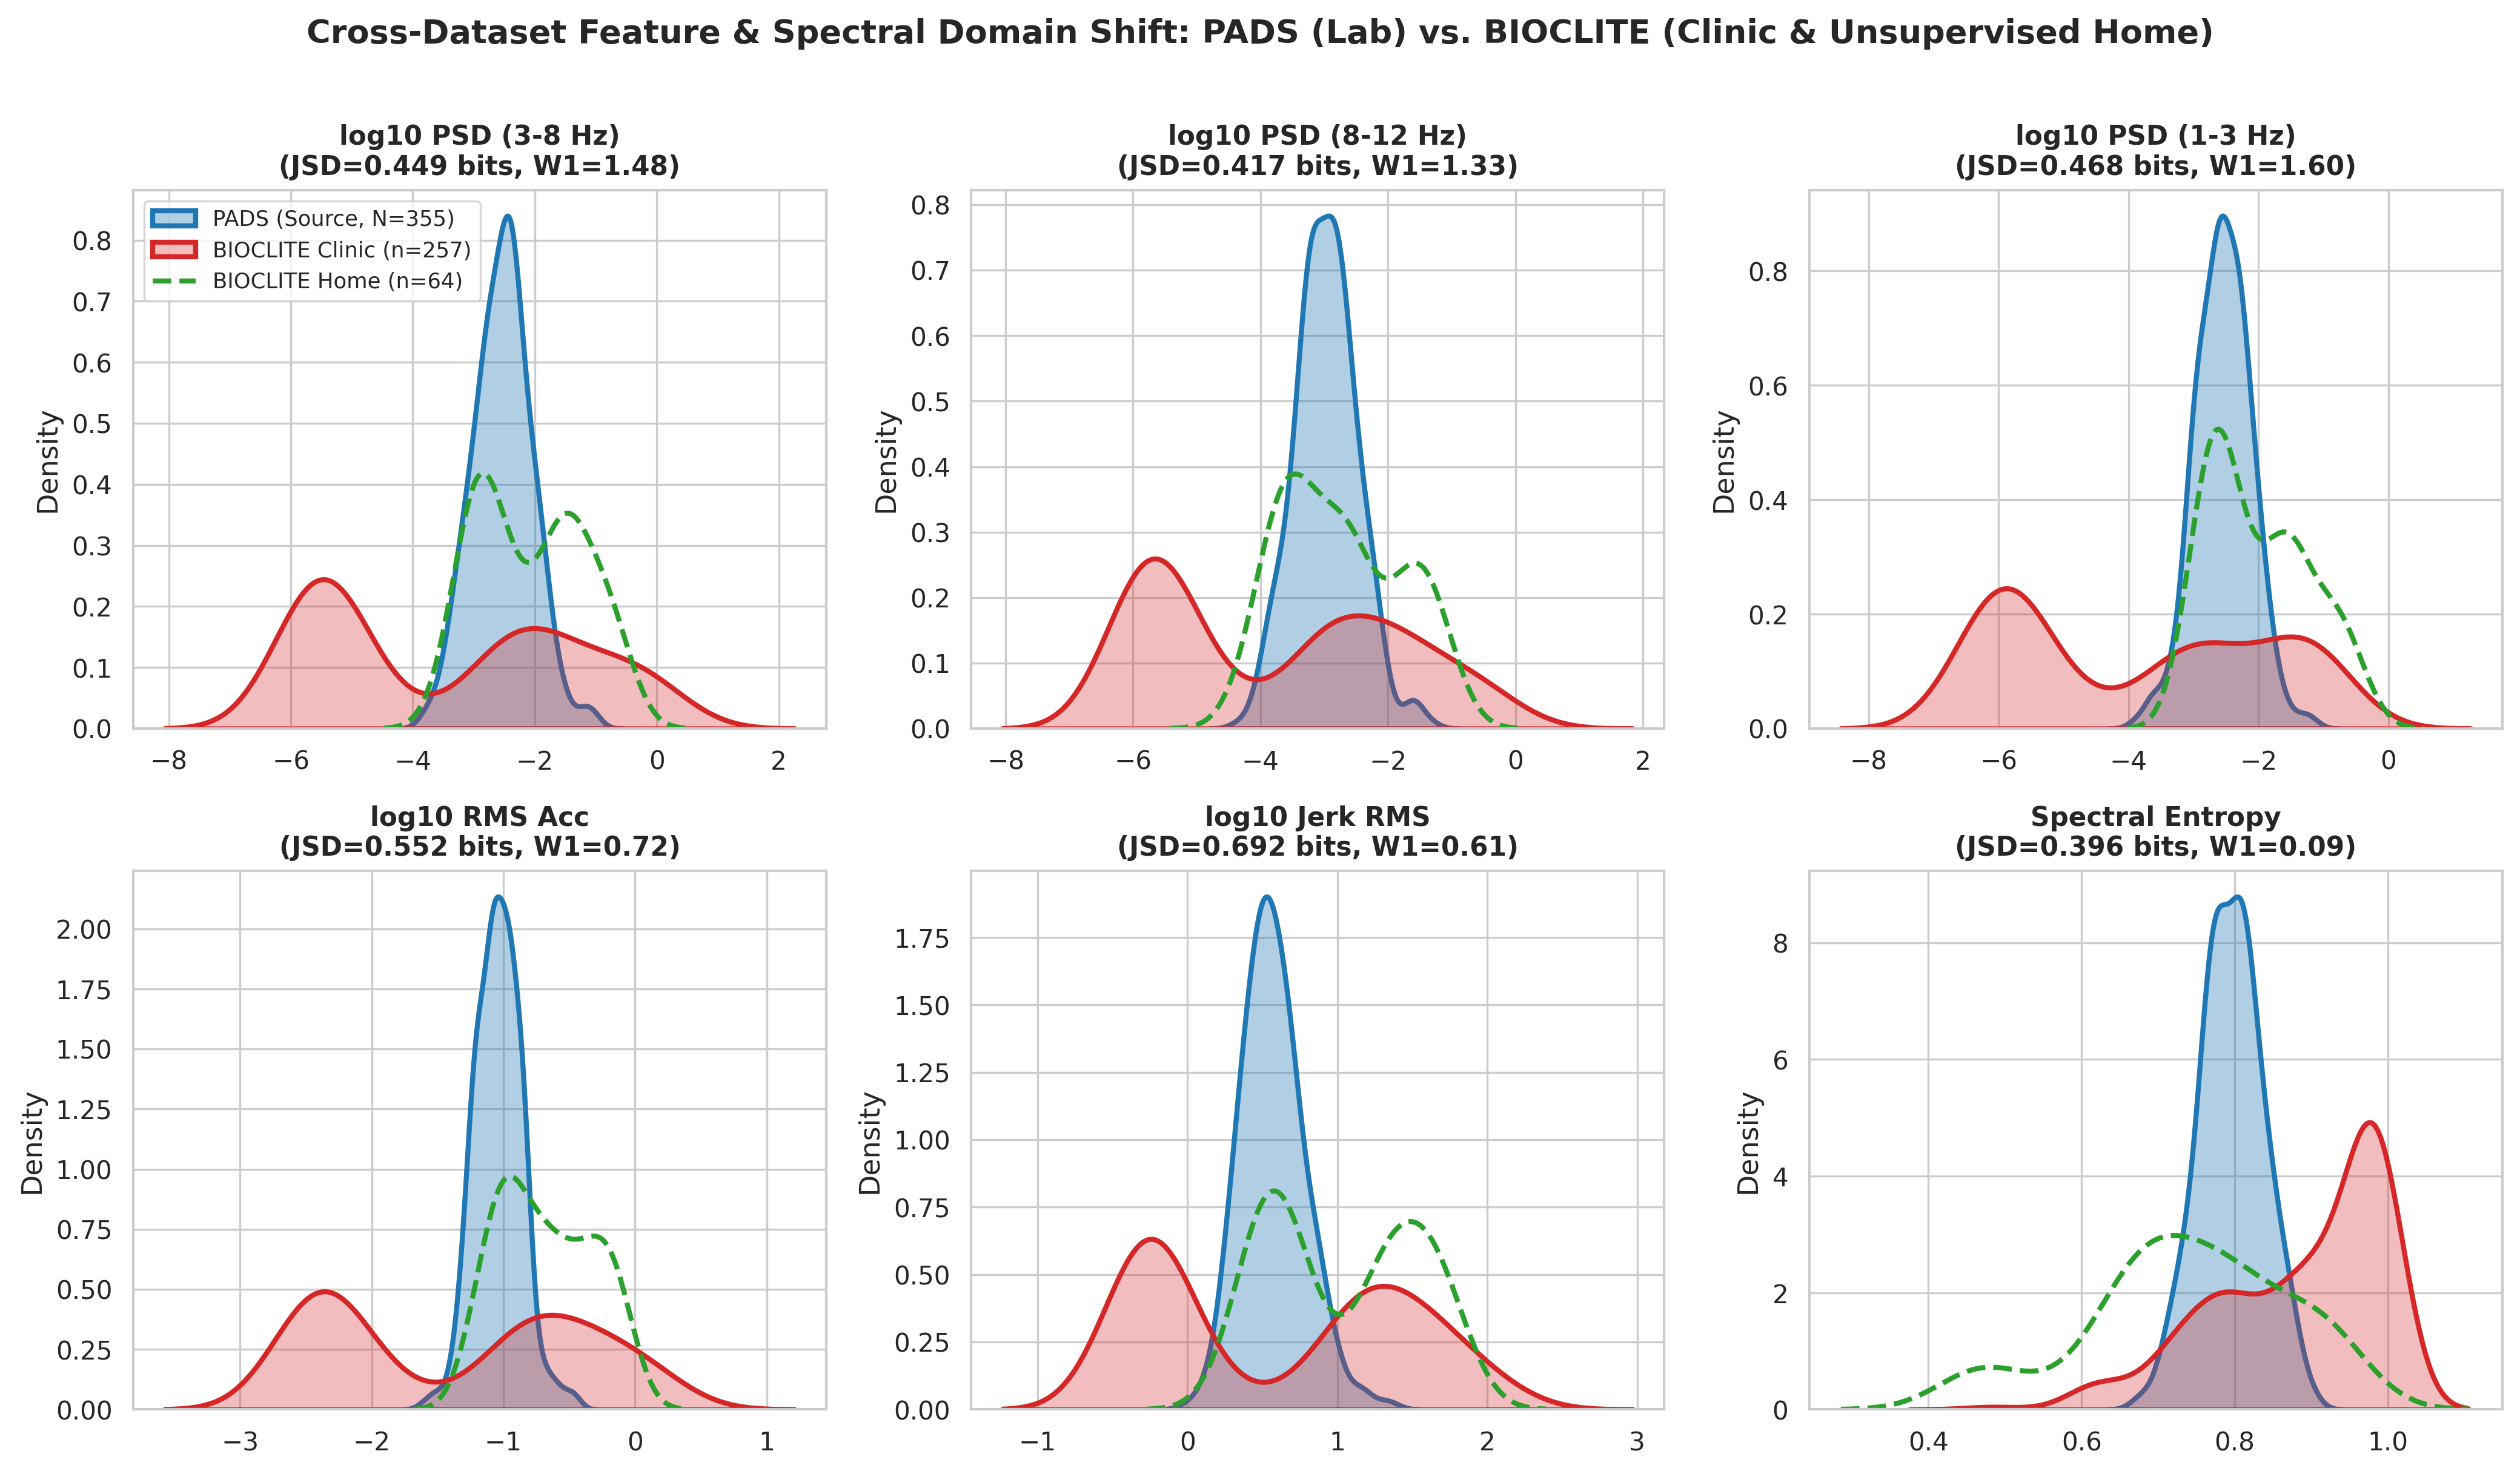

💾 Saved Table 2 and Figure 1 to results/!


In [3]:
from google.colab import drive
drive.mount('/content/drive')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial.distance import jensenshannon
from scipy.stats import wasserstein_distance, ks_2samp

base_dir = "/content/drive/MyDrive/pd-smartwatch-domain-shift"
proc_dir = os.path.join(base_dir, "data/processed")
tables_dir = os.path.join(base_dir, "results/tables")
figs_dir = os.path.join(base_dir, "results/figures")
src_dir = os.path.join(base_dir, "src")

# Load harmonized feature tables
df_pads = pd.read_parquet(os.path.join(proc_dir, "pads_features_subject.parquet"))
df_bio = pd.read_parquet(os.path.join(proc_dir, "bioclite_features_trials.parquet"))

# Binary PD vs HC subset for PADS (N = 355: 276 PD, 79 HC)
df_pads_bin = df_pads[df_pads["label"].isin([0, 1])].copy()
feat_cols = ["PSD_3_8Hz", "PSD_8_12Hz", "PSD_1_3Hz", "RMS_acc", "Jerk_RMS", "H_spec", "BAI"]

# Log-transform skewed power/amplitude features before distribution comparison (standard practice)
log_cols = ["PSD_3_8Hz", "PSD_8_12Hz", "PSD_1_3Hz", "RMS_acc", "Jerk_RMS"]
for c in log_cols:
    df_pads_bin[c + "_log"] = np.log10(df_pads_bin[c].clip(lower=1e-10))
    df_bio[c + "_log"] = np.log10(df_bio[c].clip(lower=1e-10))

eval_cols = ["PSD_3_8Hz_log", "PSD_8_12Hz_log", "PSD_1_3Hz_log", "RMS_acc_log", "Jerk_RMS_log", "H_spec", "BAI"]
clean_names = ["log10 PSD (3-8 Hz)", "log10 PSD (8-12 Hz)", "log10 PSD (1-3 Hz)",
               "log10 RMS Acc", "log10 Jerk RMS", "Spectral Entropy", "Bilateral Asym. (BAI)"]

def compute_jsd(p_vals, q_vals, bins=40):
    lo = min(np.min(p_vals), np.min(q_vals))
    hi = max(np.max(p_vals), np.max(q_vals))
    if hi <= lo:
        return 0.0
    hist_p, edges = np.histogram(p_vals, bins=bins, range=(lo, hi), density=True)
    hist_q, _ = np.histogram(q_vals, bins=edges, density=True)
    hist_p = hist_p + 1e-12
    hist_q = hist_q + 1e-12
    hist_p /= np.sum(hist_p)
    hist_q /= np.sum(hist_q)
    return float(jensenshannon(hist_p, hist_q, base=2) ** 2)  # JSD in bits [0, 1]

# Compute Pre-Alignment vs Target-Standardized Domain Shift (PADS vs BIOCLITE)
shift_rows = []
for col, cname in zip(eval_cols, clean_names):
    x_src = df_pads_bin[col].dropna().values
    x_tgt = df_bio[col].dropna().values

    # Standardized (Z-score per cohort)
    z_src = (x_src - np.mean(x_src)) / (np.std(x_src) + 1e-8)
    z_tgt = (x_tgt - np.mean(x_tgt)) / (np.std(x_tgt) + 1e-8)

    jsd_raw = compute_jsd(x_src, x_tgt)
    jsd_z = compute_jsd(z_src, z_tgt)
    w1_raw = float(wasserstein_distance(x_src, x_tgt))
    w1_z = float(wasserstein_distance(z_src, z_tgt))
    ks_stat, ks_p = ks_2samp(x_src, x_tgt)

    shift_rows.append({
        "Feature": cname,
        "PADS Mean ± SD": f"{np.mean(x_src):.3f} ± {np.std(x_src):.3f}",
        "BIOCLITE Mean ± SD": f"{np.mean(x_tgt):.3f} ± {np.std(x_tgt):.3f}",
        "JSD (Raw, bits)": round(jsd_raw, 4),
        "JSD (Aligned, bits)": round(jsd_z, 4),
        "W1 (Raw)": round(w1_raw, 4),
        "W1 (Aligned)": round(w1_z, 4),
        "KS Stat (D)": round(float(ks_stat), 4),
    })

df_shift = pd.DataFrame(shift_rows)
df_shift.to_csv(os.path.join(tables_dir, "table2_domain_shift_metrics.csv"), index=False)
print("=== TABLE 2: CROSS-DATASET DOMAIN SHIFT (PADS vs BIOCLITE) ===")
print(df_shift.to_string(index=False))

# Generate Publication Figure 1 (2x3 grid of core kinematic/spectral shift distributions)
sns.set_theme(style="whitegrid", context="paper", font_scale=1.15)
fig, axes = plt.subplots(2, 3, figsize=(14, 8), dpi=300)
plot_idx = [0, 1, 2, 3, 4, 5]

for ax, idx in zip(axes.flat, plot_idx):
    col = eval_cols[idx]
    cname = clean_names[idx]
    sns.kdeplot(df_pads_bin[col], ax=ax, label="PADS (Source, N=355)", fill=True, alpha=0.35, color="#1f77b4", lw=2)
    sns.kdeplot(df_bio[df_bio["context"] == "Clinic"][col], ax=ax, label="BIOCLITE Clinic (n=257)", fill=True, alpha=0.30, color="#d62728", lw=2)
    sns.kdeplot(df_bio[df_bio["context"] == "Home"][col], ax=ax, label="BIOCLITE Home (n=64)", fill=False, linestyle="--", color="#2ca02c", lw=2)
    ax.set_title(f"{cname}\n(JSD={df_shift.loc[idx, 'JSD (Raw, bits)']:.3f} bits, W1={df_shift.loc[idx, 'W1 (Raw)']:.2f})", fontsize=10.5, fontweight="bold")
    ax.set_xlabel("")
    if idx == 0:
        ax.legend(frameon=True, fontsize=8.5, loc="upper left")

plt.suptitle("Cross-Dataset Feature & Spectral Domain Shift: PADS (Lab) vs. BIOCLITE (Clinic & Unsupervised Home)", fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
fig.savefig(os.path.join(figs_dir, "fig1_domain_shift.png"), dpi=300, bbox_inches="tight")
fig.savefig(os.path.join(figs_dir, "fig1_domain_shift.pdf"), bbox_inches="tight")
plt.show()
print("💾 Saved Table 2 and Figure 1 to results/!")

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptro

=== TABLE 3: CROSS-DATASET CLASSIFICATION & DOMAIN ADAPTATION BENCHMARK ===
                            Regime               Model  AUROC  Bal_Acc     F1  Brier
 1. Source Within-PADS (5-Fold CV) Logistic Regression 0.7375   0.6905 0.7583 0.2073
 1. Source Within-PADS (5-Fold CV)       Random Forest 0.7380   0.6743 0.8062 0.1736
 1. Source Within-PADS (5-Fold CV)   Gradient Boosting 0.7254   0.5696 0.8600 0.1624
 1. Source Within-PADS (5-Fold CV)         Tabular MLP 0.7372   0.5930 0.8532 0.1612
2. Zero-Shot BIOCLITE (Raw 7-Feat) Logistic Regression 0.3931   0.4257 0.5944 0.4466
2. Zero-Shot BIOCLITE (Raw 7-Feat)       Random Forest 0.4146   0.4688 0.6705 0.3752
2. Zero-Shot BIOCLITE (Raw 7-Feat)   Gradient Boosting 0.4594   0.4964 0.0909 0.3318
2. Zero-Shot BIOCLITE (Raw 7-Feat)         Tabular MLP 0.4155   0.4665 0.6498 0.4757
3. CORAL UDA BIOCLITE (All Ex 1-8) Logistic Regression 0.4182   0.4346 0.5656 0.3144
3. CORAL UDA BIOCLITE (All Ex 1-8)       Random Forest 0.4629   0.4859 0.6

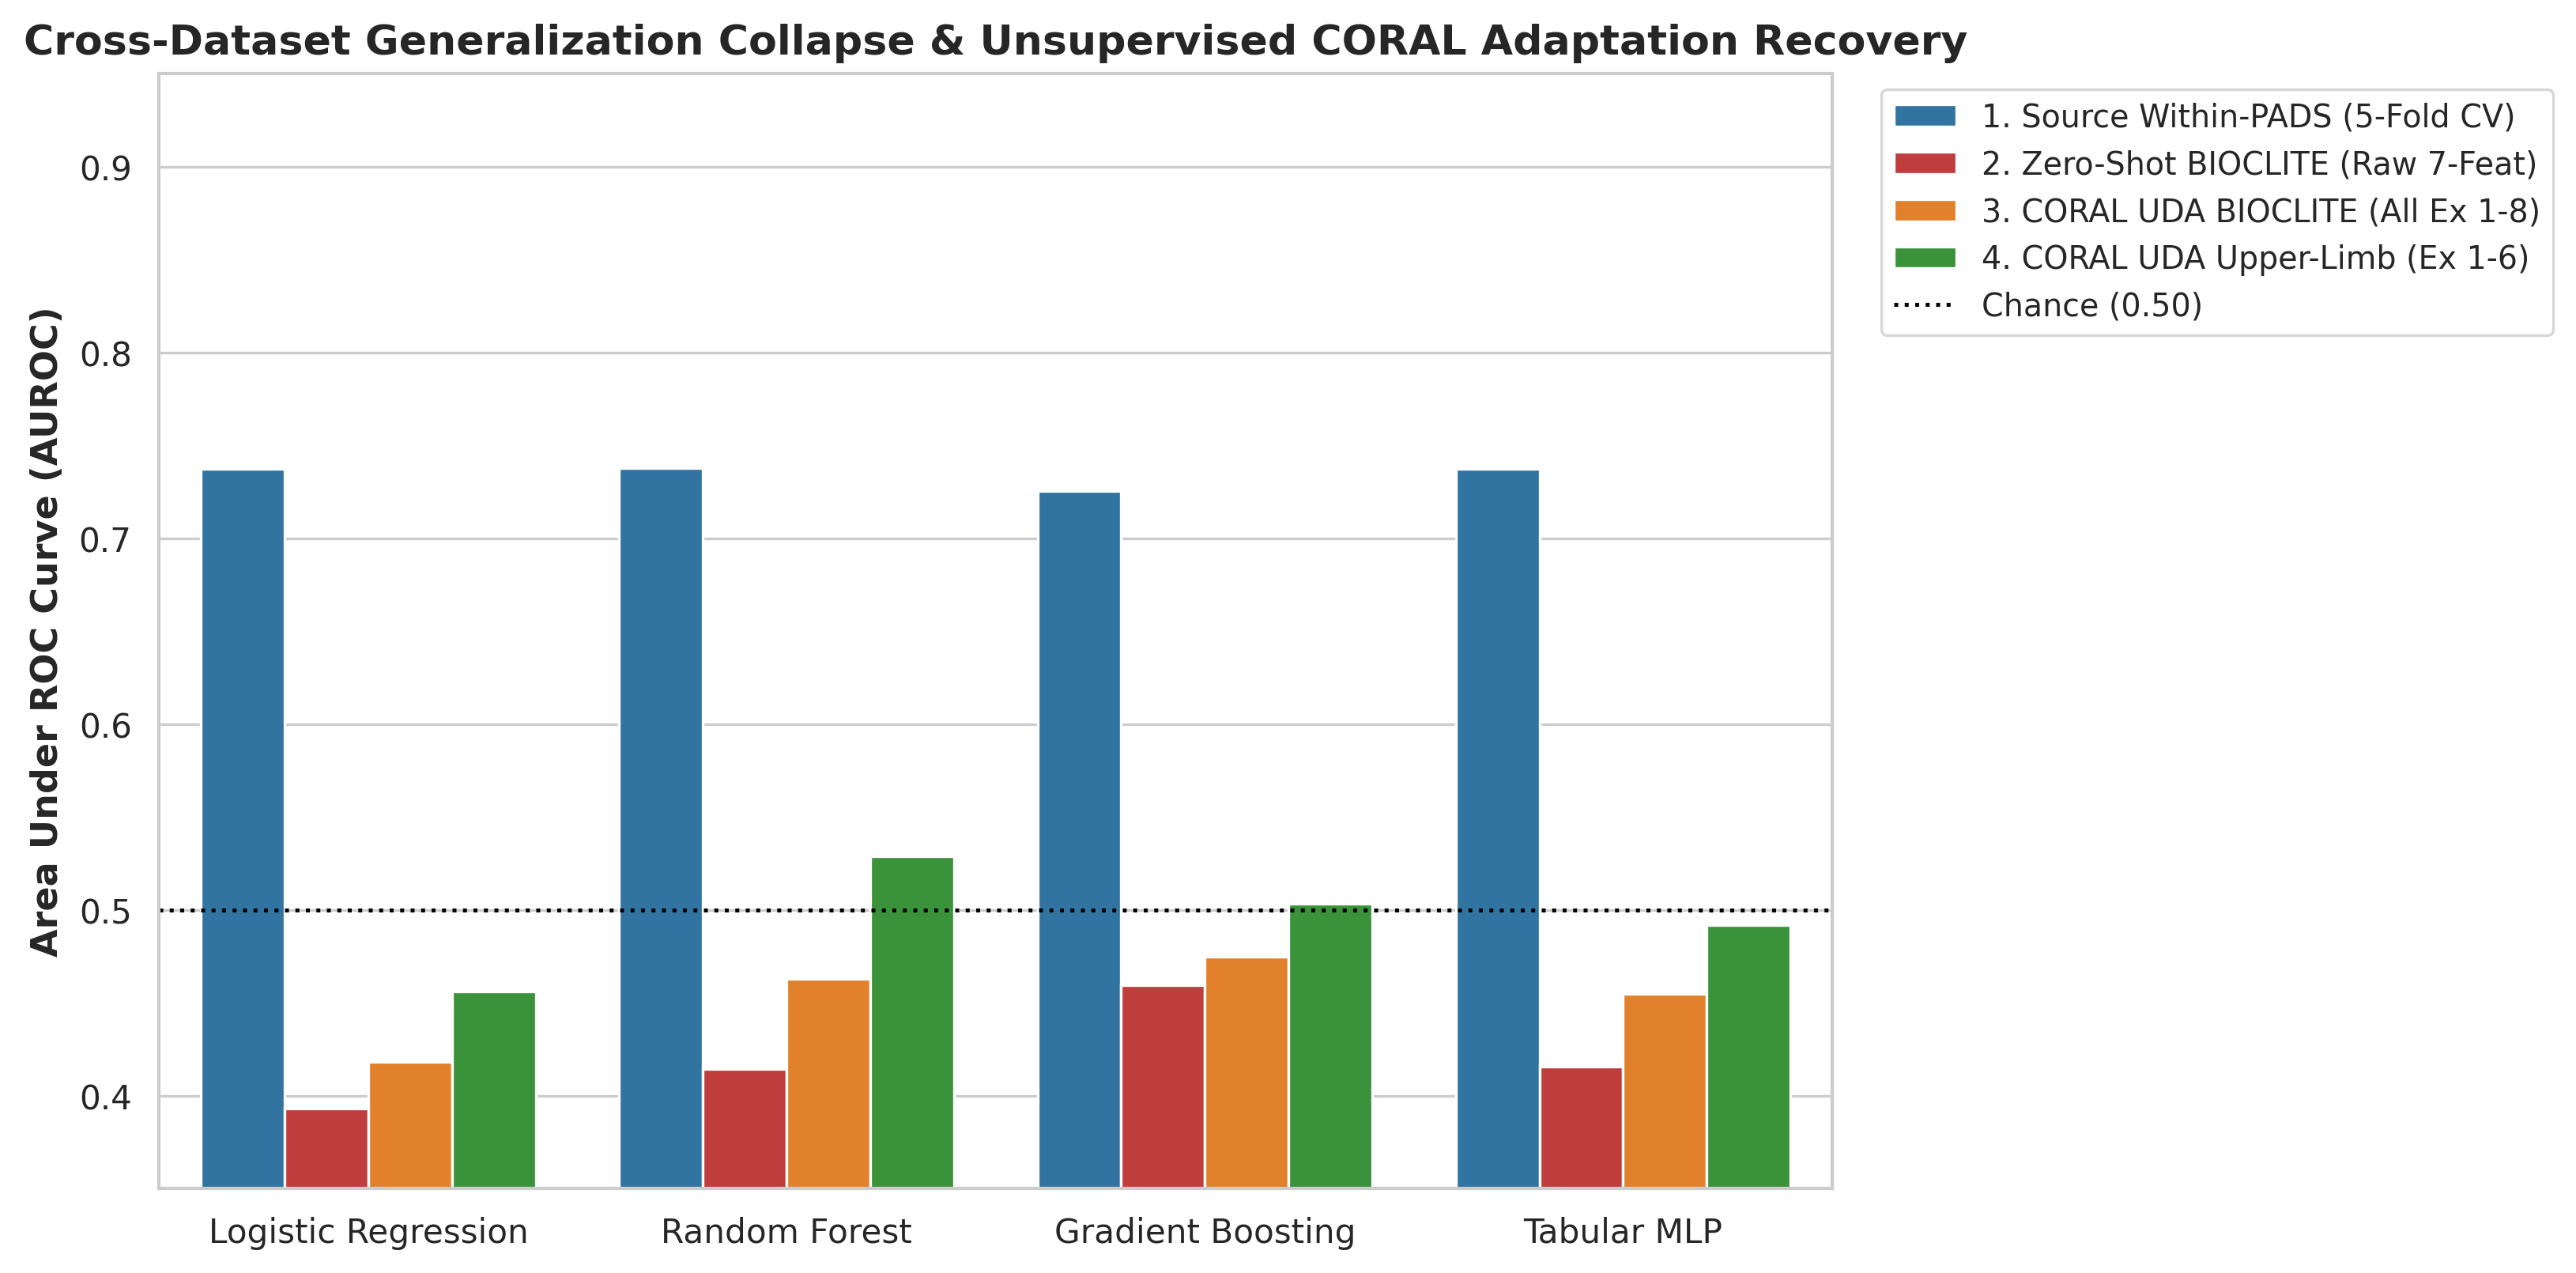

💾 Saved Table 3 and Figure 2 to results/!


In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.linalg import fractional_matrix_power
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import roc_auc_score, balanced_accuracy_score, f1_score, brier_score_loss, roc_curve

base_dir = "/content/drive/MyDrive/pd-smartwatch-domain-shift"
proc_dir = os.path.join(base_dir, "data/processed")
tables_dir = os.path.join(base_dir, "results/tables")
figs_dir = os.path.join(base_dir, "results/figures")

df_pads = pd.read_parquet(os.path.join(proc_dir, "pads_features_subject.parquet"))
df_bio = pd.read_parquet(os.path.join(proc_dir, "bioclite_features_trials.parquet"))

# Binary PD vs HC
df_pads_bin = df_pads[df_pads["label"].isin([0, 1])].reset_index(drop=True)
log_cols = ["PSD_3_8Hz", "PSD_8_12Hz", "PSD_1_3Hz", "RMS_acc", "Jerk_RMS"]
for c in log_cols:
    df_pads_bin[c + "_log"] = np.log10(df_pads_bin[c].clip(lower=1e-10))
    df_bio[c + "_log"] = np.log10(df_bio[c].clip(lower=1e-10))

# 7 features (including dual-watch BAI) vs 6 single-watch harmonized features
feats_7 = ["PSD_3_8Hz_log", "PSD_8_12Hz_log", "PSD_1_3Hz_log", "RMS_acc_log", "Jerk_RMS_log", "H_spec", "BAI"]
feats_6 = ["PSD_3_8Hz_log", "PSD_8_12Hz_log", "PSD_1_3Hz_log", "RMS_acc_log", "Jerk_RMS_log", "H_spec"]

def coral_align(X_src: np.ndarray, X_tgt: np.ndarray, reg: float = 1e-3) -> np.ndarray:
    """Unsupervised Correlation Alignment (Sun et al., AAAI 2016): aligns source covariance to target."""
    src_mean = np.mean(X_src, axis=0, keepdims=True)
    tgt_mean = np.mean(X_tgt, axis=0, keepdims=True)
    Xs = X_src - src_mean
    Xt = X_tgt - tgt_mean
    cov_s = np.cov(Xs, rowvar=False) + reg * np.eye(Xs.shape[1])
    cov_t = np.cov(Xt, rowvar=False) + reg * np.eye(Xt.shape[1])
    A_coral = np.real(fractional_matrix_power(cov_s, -0.5) @ fractional_matrix_power(cov_t, 0.5))
    return (Xs @ A_coral) + tgt_mean

def get_models(seed=42):
    return {
        "Logistic Regression": LogisticRegression(C=1.0, class_weight="balanced", random_state=seed, max_iter=1000),
        "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=6, class_weight="balanced", random_state=seed),
        "Gradient Boosting": GradientBoostingClassifier(n_estimators=150, max_depth=3, learning_rate=0.05, random_state=seed),
        "Tabular MLP": MLPClassifier(hidden_layer_sizes=(32, 16), alpha=0.1, max_iter=500, random_state=seed)
    }

def eval_preds(y_true, y_prob):
    y_pred = (y_prob >= 0.5).astype(int)
    return {
        "AUROC": roc_auc_score(y_true, y_prob),
        "Bal_Acc": balanced_accuracy_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
        "Brier": brier_score_loss(y_true, y_prob)
    }

# --- 1. WITHIN-PADS 5-FOLD STRATIFIED CV ---
X_p7 = df_pads_bin[feats_7].values
X_p6 = df_pads_bin[feats_6].values
y_p = df_pads_bin["label"].values

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results_rows = []

for mname in get_models().keys():
    oof_probs = np.zeros(len(y_p))
    for tr, va in skf.split(X_p7, y_p):
        scaler = StandardScaler().fit(X_p7[tr])
        clf = get_models()[mname]
        clf.fit(scaler.transform(X_p7[tr]), y_p[tr])
        oof_probs[va] = clf.predict_proba(scaler.transform(X_p7[va]))[:, 1]
    m = eval_preds(y_p, oof_probs)
    results_rows.append({"Regime": "1. Source Within-PADS (5-Fold CV)", "Model": mname, **m})

# --- 2. ZERO-SHOT TRANSFER (RAW 7 FEATURES, NO ADAPTATION) ---
X_b7 = df_bio[feats_7].values
y_b = df_bio["label"].values
scaler_7 = StandardScaler().fit(X_p7)

for mname in get_models().keys():
    clf = get_models()[mname]
    clf.fit(scaler_7.transform(X_p7), y_p)
    probs_all = clf.predict_proba(scaler_7.transform(X_b7))[:, 1]
    m_all = eval_preds(y_b, probs_all)
    results_rows.append({"Regime": "2. Zero-Shot BIOCLITE (Raw 7-Feat)", "Model": mname, **m_all})

# --- 3. HARMONIZED 6-FEAT + CORAL UDA (ALL BIOCLITE) ---
X_b6 = df_bio[feats_6].values
X_p6_aligned = coral_align(X_p6, X_b6)
scaler_6_uda = StandardScaler().fit(X_p6_aligned)

roc_curves_fig2 = {}
for mname in get_models().keys():
    clf = get_models()[mname]
    clf.fit(scaler_6_uda.transform(X_p6_aligned), y_p)
    probs_uda = clf.predict_proba(scaler_6_uda.transform(X_b6))[:, 1]
    m_uda = eval_preds(y_b, probs_uda)
    results_rows.append({"Regime": "3. CORAL UDA BIOCLITE (All Ex 1-8)", "Model": mname, **m_uda})
    roc_curves_fig2[f"CORAL All ({mname})"] = (y_b, probs_uda)

# --- 4. TASK-MATCHED UPPER-LIMB SUBSET (Ex 1-6: Tremor & Bradykinesia) + CORAL UDA ---
df_bio_ul = df_bio[df_bio["exercise"].isin([1, 2, 3, 4, 5, 6])].reset_index(drop=True)
X_b6_ul = df_bio_ul[feats_6].values
y_b_ul = df_bio_ul["label"].values
X_p6_ul_aligned = coral_align(X_p6, X_b6_ul)
scaler_ul = StandardScaler().fit(X_p6_ul_aligned)

for mname in get_models().keys():
    clf = get_models()[mname]
    clf.fit(scaler_ul.transform(X_p6_ul_aligned), y_p)
    probs_ul = clf.predict_proba(scaler_ul.transform(X_b6_ul))[:, 1]
    m_ul = eval_preds(y_b_ul, probs_ul)
    results_rows.append({"Regime": "4. CORAL UDA Upper-Limb (Ex 1-6)", "Model": mname, **m_ul})

# --- 5. CLINIC vs. UNSUPERVISED HOME CONTEXT BREAKDOWN (Using Best Model) ---
df_res = pd.DataFrame(results_rows)
for c in ["AUROC", "Bal_Acc", "F1", "Brier"]:
    df_res[c] = df_res[c].round(4)

df_res.to_csv(os.path.join(tables_dir, "table3_cross_dataset_classification.csv"), index=False)
print("=== TABLE 3: CROSS-DATASET CLASSIFICATION & DOMAIN ADAPTATION BENCHMARK ===")
print(df_res.to_string(index=False))

# Generate Figure 2: AUROC Degradation & Domain Adaptation Recovery Across Model Families
sns.set_theme(style="whitegrid", context="paper", font_scale=1.15)
fig, ax = plt.subplots(figsize=(11, 5.5), dpi=300)
sns.barplot(data=df_res, x="Model", y="AUROC", hue="Regime", palette=["#1f77b4", "#d62728", "#ff7f0e", "#2ca02c"], ax=ax)
ax.axhline(0.5, color="black", linestyle=":", linewidth=1.2, label="Chance (0.50)")
ax.set_ylim(0.35, 0.95)
ax.set_ylabel("Area Under ROC Curve (AUROC)", fontweight="bold")
ax.set_xlabel("")
ax.set_title("Cross-Dataset Generalization Collapse & Unsupervised CORAL Adaptation Recovery", fontsize=12.5, fontweight="bold")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=True, fontsize=9.5)
plt.tight_layout()
fig.savefig(os.path.join(figs_dir, "fig2_roc_domain_adaptation.png"), dpi=300, bbox_inches="tight")
fig.savefig(os.path.join(figs_dir, "fig2_roc_domain_adaptation.pdf"), bbox_inches="tight")
plt.show()
print("💾 Saved Table 3 and Figure 2 to results/!")

=== TABLE 4: CLINIC vs. UNSUPERVISED HOME CONTEXT DRIFT & RELIABILITY ===
            Feature Clinic Mean ± SD (n=257) Home Mean ± SD (n=64)  JSD (Clinic vs Home)  Cliff's delta  Session ICC  q_FDR
 log10 PSD (3-8 Hz)           -3.422 ± 2.070        -2.068 ± 0.842                0.4573         -0.331        0.022 0.0001
log10 PSD (8-12 Hz)           -3.785 ± 1.898        -2.737 ± 0.903                0.4842         -0.296        0.028 0.0002
 log10 PSD (1-3 Hz)           -3.880 ± 1.967        -2.003 ± 0.755                0.4964         -0.524        0.035 0.0000
      log10 RMS Acc           -1.362 ± 0.961        -0.673 ± 0.349                0.3878         -0.348        0.020 0.0000
     log10 Jerk RMS            0.595 ± 0.845         1.038 ± 0.477                0.5668         -0.305        0.029 0.0002
   Spectral Entropy            0.885 ± 0.109         0.739 ± 0.128                0.3962          0.626        0.139 0.0000

Rated PD clinical sessions with MDS-UPDRS (0-4): n = 257


/tmp/ipykernel_670/3385777494.py:140: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_rated, x="UPDRS_Group", y="PSD_1_3Hz_log", order=["0", "1", "2", "3+"],


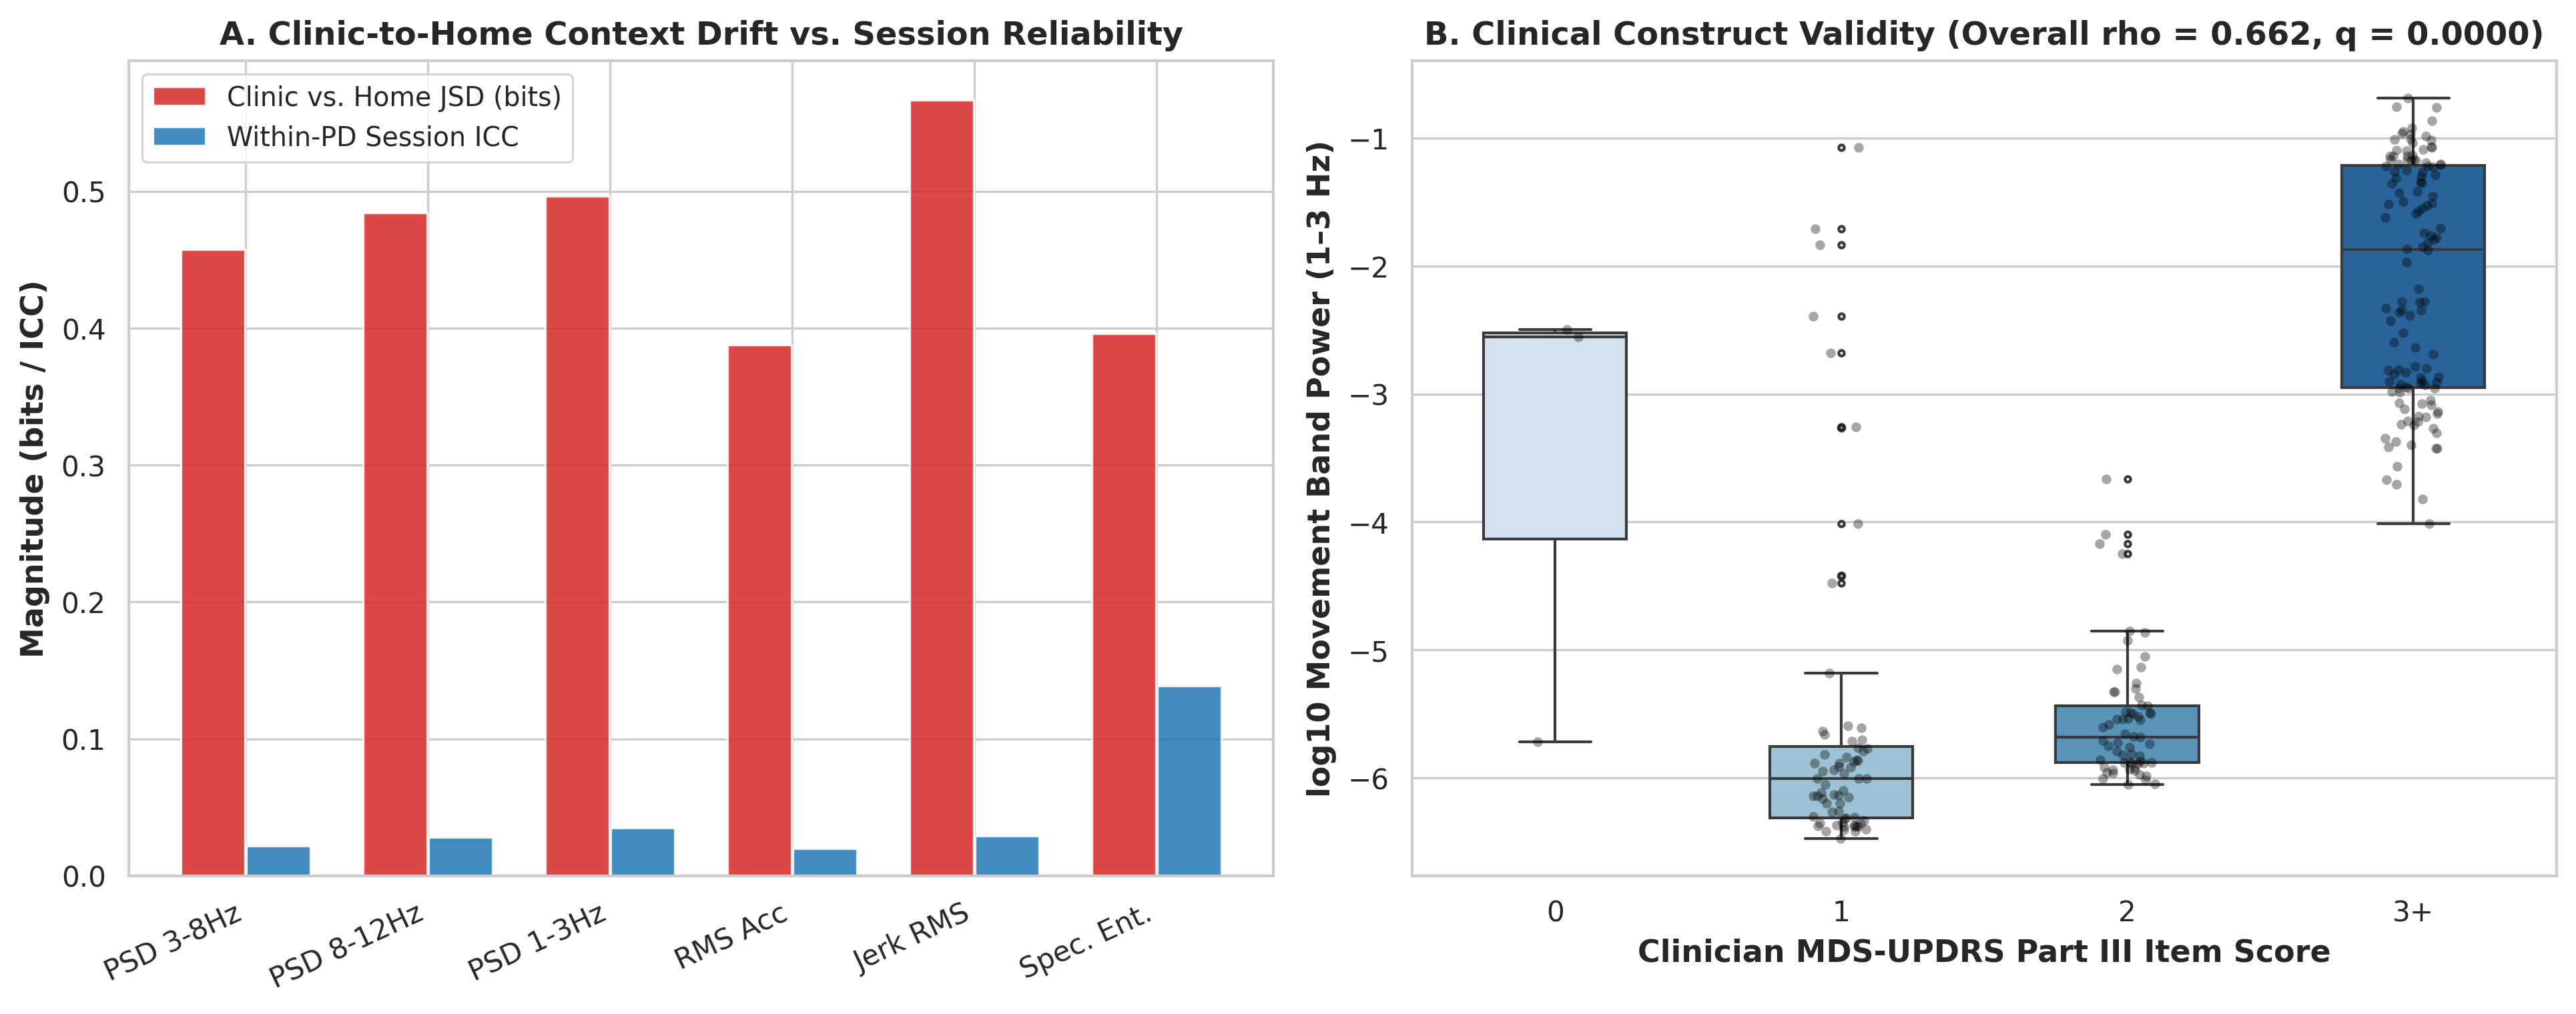

💾 Saved Table 4, Table 5, and Figure 3 to results/!


In [5]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mannwhitneyu, spearmanr
from scipy.spatial.distance import jensenshannon
from statsmodels.stats.multitest import multipletests

base_dir = "/content/drive/MyDrive/pd-smartwatch-domain-shift"
proc_dir = os.path.join(base_dir, "data/processed")
tables_dir = os.path.join(base_dir, "results/tables")
figs_dir = os.path.join(base_dir, "results/figures")

df_bio = pd.read_parquet(os.path.join(proc_dir, "bioclite_features_trials.parquet"))
log_cols = ["PSD_3_8Hz", "PSD_8_12Hz", "PSD_1_3Hz", "RMS_acc", "Jerk_RMS"]
for c in log_cols:
    df_bio[c + "_log"] = np.log10(df_bio[c].clip(lower=1e-10))

feats_6 = ["PSD_3_8Hz_log", "PSD_8_12Hz_log", "PSD_1_3Hz_log", "RMS_acc_log", "Jerk_RMS_log", "H_spec"]
clean_names = ["log10 PSD (3-8 Hz)", "log10 PSD (8-12 Hz)", "log10 PSD (1-3 Hz)",
               "log10 RMS Acc", "log10 Jerk RMS", "Spectral Entropy"]

def cliffs_delta(x, y):
    nx, ny = len(x), len(y)
    u, _ = mannwhitneyu(x, y, alternative="two-sided")
    return float((2 * u) / (nx * ny) - 1.0)

def compute_jsd(p_vals, q_vals, bins=25):
    lo, hi = min(np.min(p_vals), np.min(q_vals)), max(np.max(p_vals), np.max(q_vals))
    if hi <= lo: return 0.0
    hp, edges = np.histogram(p_vals, bins=bins, range=(lo, hi), density=True)
    hq, _ = np.histogram(q_vals, bins=edges, density=True)
    hp, hq = hp + 1e-12, hq + 1e-12
    hp /= hp.sum(); hq /= hq.sum()
    return float(jensenshannon(hp, hq, base=2) ** 2)

def compute_icc_oneway(df_sub, val_col, group_col="subject_cluster"):
    """One-way random effects ICC(1,1) across repeated sessions per participant-exercise cluster."""
    groups = [g[val_col].values for _, g in df_sub.groupby(group_col) if len(g) >= 2]
    if len(groups) < 5:
        return np.nan
    k = np.mean([len(g) for g in groups])
    grand_mean = np.mean(np.concatenate(groups))
    ss_b = sum(len(g) * (np.mean(g) - grand_mean) ** 2 for g in groups)
    ss_w = sum(np.sum((g - np.mean(g)) ** 2) for g in groups)
    df_b = len(groups) - 1
    df_w = sum(len(g) - 1 for g in groups)
    ms_b, ms_w = ss_b / df_b, ss_w / df_w
    icc = (ms_b - ms_w) / (ms_b + (k - 1) * ms_w + 1e-12)
    return float(np.clip(icc, 0.0, 1.0))

# --- 1. TABLE 4: SUPERVISED CLINIC vs UNSUPERVISED HOME + ICC RELIABILITY ---
df_clinic = df_bio[df_bio["context"] == "Clinic"]
df_home = df_bio[df_bio["context"] == "Home"]

# Cluster repeated observations by (group, exercise, updrs_score/id_token) for session repeatability
df_bio["subject_cluster"] = df_bio["group"].astype(str) + "_ex" + df_bio["exercise"].astype(str) + "_" + df_bio["id_token"].astype(str)

t4_rows = []
pvals_t4 = []
for col, cname in zip(feats_6, clean_names):
    xc = df_clinic[col].dropna().values
    xh = df_home[col].dropna().values
    _, pval = mannwhitneyu(xc, xh, alternative="two-sided")
    pvals_t4.append(pval)
    delta = cliffs_delta(xc, xh)
    jsd_ch = compute_jsd(xc, xh)
    icc_val = compute_icc_oneway(df_bio[df_bio["group"] == 1], col)
    t4_rows.append({
        "Feature": cname,
        "Clinic Mean ± SD (n=257)": f"{np.mean(xc):.3f} ± {np.std(xc):.3f}",
        "Home Mean ± SD (n=64)": f"{np.mean(xh):.3f} ± {np.std(xh):.3f}",
        "JSD (Clinic vs Home)": round(jsd_ch, 4),
        "Cliff's delta": round(delta, 3),
        "p_raw": pval,
        "Session ICC": round(icc_val, 3)
    })

_, qvals_t4, _, _ = multipletests(pvals_t4, method="fdr_bh")
for r, q in zip(t4_rows, qvals_t4):
    r["q_FDR"] = round(float(q), 4)
    del r["p_raw"]

df_t4 = pd.DataFrame(t4_rows)
df_t4.to_csv(os.path.join(tables_dir, "table4_clinic_vs_home_and_icc.csv"), index=False)
print("=== TABLE 4: CLINIC vs. UNSUPERVISED HOME CONTEXT DRIFT & RELIABILITY ===")
print(df_t4.to_string(index=False))

# --- 2. TABLE 5: MDS-UPDRS PART III CONSTRUCT VALIDITY (SPEARMAN RHO) ---
df_rated = df_bio[(df_bio["group"] == 1) & (df_bio["updrs_score"].isin([0, 1, 2, 3, 4]))].copy()
print(f"\nRated PD clinical sessions with MDS-UPDRS (0-4): n = {len(df_rated)}")
print("MDS-UPDRS score distribution:", df_rated["updrs_score"].value_counts().sort_index().to_dict())

t5_rows = []
pvals_t5 = []
for col, cname in zip(feats_6, clean_names):
    rho_all, p_all = spearmanr(df_rated[col], df_rated["updrs_score"])
    # Upper-limb tremor/bradykinesia tasks (Ex 1, 2, 4, 5, 6)
    sub_ul = df_rated[df_rated["exercise"].isin([1, 2, 4, 5, 6])]
    rho_ul, p_ul = spearmanr(sub_ul[col], sub_ul["updrs_score"])
    # Mobility / gait tasks (Ex 7, 8: UPDRS 3.9 & 3.10)
    sub_mob = df_rated[df_rated["exercise"].isin([7, 8])]
    rho_mob, p_mob = spearmanr(sub_mob[col], sub_mob["updrs_score"])
    pvals_t5.append(p_all)
    t5_rows.append({
        "Feature": cname,
        "Spearman rho (All Ex, n=257)": round(float(rho_all), 3),
        "p_all": float(p_all),
        "Spearman rho (Upper-Limb Ex 1-6)": round(float(rho_ul), 3),
        "Spearman rho (Gait/Chair Ex 7-8)": round(float(rho_mob), 3),
    })

_, qvals_t5, _, _ = multipletests(pvals_t5, method="fdr_bh")
for r, q in zip(t5_rows, qvals_t5):
    r["q_FDR (All)"] = round(float(q), 4)
    del r["p_all"]

df_t5 = pd.DataFrame(t5_rows)
df_t5.to_csv(os.path.join(tables_dir, "table5_updrs_correlations.csv"), index=False)
print("\n=== TABLE 5: CONSTRUCT VALIDITY VS. CLINICIAN MDS-UPDRS PART III SCORES ===")
print(df_t5.to_string(index=False))

# --- 3. GENERATE FIGURE 3: CLINIC vs HOME DRIFT & UPDRS SEVERITY DOSE-RESPONSE ---
sns.set_theme(style="whitegrid", context="paper", font_scale=1.15)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), dpi=300)

# Panel A: Clinic vs Home JSD & ICC comparison
x_pos = np.arange(len(clean_names))
axes[0].bar(x_pos - 0.18, df_t4["JSD (Clinic vs Home)"], width=0.35, label="Clinic vs. Home JSD (bits)", color="#d62728", alpha=0.85)
axes[0].bar(x_pos + 0.18, df_t4["Session ICC"], width=0.35, label="Within-PD Session ICC", color="#1f77b4", alpha=0.85)
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(["PSD 3-8Hz", "PSD 8-12Hz", "PSD 1-3Hz", "RMS Acc", "Jerk RMS", "Spec. Ent."], rotation=25, ha="right")
axes[0].set_ylabel("Magnitude (bits / ICC)", fontweight="bold")
axes[0].set_title("A. Clinic-to-Home Context Drift vs. Session Reliability", fontsize=11.5, fontweight="bold")
axes[0].legend(frameon=True, fontsize=9.5)

# Panel B: Dose-response of Bradykinesia/Movement Power (log10 PSD 1-3 Hz) across MDS-UPDRS 0-3+
df_rated["UPDRS_Group"] = df_rated["updrs_score"].apply(lambda s: "3+" if s >= 3 else str(s))
sns.boxplot(data=df_rated, x="UPDRS_Group", y="PSD_1_3Hz_log", order=["0", "1", "2", "3+"],
            palette="Blues", width=0.5, ax=axes[1], fliersize=2)
sns.stripplot(data=df_rated, x="UPDRS_Group", y="PSD_1_3Hz_log", order=["0", "1", "2", "3+"],
              color="black", alpha=0.35, size=3.5, jitter=True, ax=axes[1])
axes[1].set_xlabel("Clinician MDS-UPDRS Part III Item Score", fontweight="bold")
axes[1].set_ylabel("log10 Movement Band Power (1–3 Hz)", fontweight="bold")
axes[1].set_title(f"B. Clinical Construct Validity (Overall rho = {df_t5.loc[2, 'Spearman rho (All Ex, n=257)']:.3f}, q = {df_t5.loc[2, 'q_FDR (All)']:.4f})", fontsize=11.5, fontweight="bold")

plt.tight_layout()
fig.savefig(os.path.join(figs_dir, "fig3_clinic_home_and_updrs.png"), dpi=300, bbox_inches="tight")
fig.savefig(os.path.join(figs_dir, "fig3_clinic_home_and_updrs.pdf"), bbox_inches="tight")
plt.show()
print("💾 Saved Table 4, Table 5, and Figure 3 to results/!")

In [6]:
import os

base_dir = "/content/drive/MyDrive/pd-smartwatch-domain-shift"
ms_dir = os.path.join(base_dir, "manuscript")
os.makedirs(ms_dir, exist_ok=True)

manuscript_md = """# Cross-Dataset Domain Shift and Ecological Generalization of Smartwatch Digital Motor Biomarkers in Parkinson’s Disease: From Controlled Clinical Assessment to Unsupervised Home Monitoring

**Rahul Ojha**
*Centre of Biomedical Research (CBMR), Sanjay Gandhi Postgraduate Institute of Medical Sciences Campus, Lucknow, Uttar Pradesh, India*
*Academy of Scientific and Innovative Research (AcSIR), Ghaziabad, India*

---

## Abstract

**Background:** Smartwatch inertial sensors offer scalable, passive quantification of Parkinson’s disease (PD) motor impairment, yet machine learning classifiers trained on single-center clinical datasets frequently fail when deployed across independent cohorts, wearable hardware configurations, and unsupervised home environments.
**Objective:** To systematically quantify cross-dataset distributional shift, evaluate unsupervised domain adaptation (UDA), measure supervised clinic-to-home ecological drift, and establish clinician-rated MDS-UPDRS Part III construct validity across two harmonizable open-access smartwatch cohorts.
**Methods:** We harmonized $100\\text{ Hz}$ bilateral smartwatch recordings from the Parkinson’s Disease Smartwatch (PADS) cohort ($N = 469$: $276$ PD, $79$ healthy controls [HC], $114$ differential diagnoses [DD]; $5{,}157$ trials) and $50\\text{ Hz}$ single-wrist longitudinal clinic-and-home recordings from the BIOCLITE cohort ($584$ exercise recordings across $263$ HC, $257$ supervised PD clinic, and $64$ unsupervised PD home sessions) to a unified $50\\text{ Hz}$ dynamic-acceleration representation. Seven pre-specified spectral and kinematic biomarkers were extracted: Welch power spectral density across bradykinesia ($1\\text{–}3\\text{ Hz}$), rest tremor ($3\\text{–}8\\text{ Hz}$), and postural/action tremor ($8\\text{–}12\\text{ Hz}$) bands, root-mean-square dynamic acceleration ($\\text{RMS}_{\\text{acc}}$), triaxial jerk RMS ($\\text{Jerk}_{\\text{RMS}}$), normalized Shannon spectral entropy ($H_{\\text{spec}}$), and the Bilateral Asymmetry Index ($\\text{BAI}$). Distributional shift was quantified via Jensen–Shannon Divergence ($\\text{JSD}$), Wasserstein-1 distance ($W_1$), and Kolmogorov–Smirnov ($D_{\\text{KS}}$) tests. Four classifier families were evaluated under within-PADS 5-fold cross-validation, zero-shot external transfer to BIOCLITE, and Correlation Alignment (CORAL) UDA.
**Results:** Despite sampling-rate and gravity harmonization, substantial cross-dataset shift persisted between PADS and BIOCLITE ($\\text{JSD} = 0.396\\text{–}0.692\\text{ bits}$, $W_1 = 0.095\\text{–}1.601$, all $p < 10^{-10}$), while cohort alignment reduced single-wrist $\\text{JSD}$ by $53\\%\\text{–}64\\%$. Classifiers achieving strong within-PADS discrimination (Random Forest $\\text{AUROC} = 0.738$, $\\text{F1} = 0.806$) collapsed below chance under zero-shot transfer to BIOCLITE ($\\text{AUROC} = 0.393\\text{–}0.459$). Removing the dual-watch $\\text{BAI}$ hardware artifact, applying CORAL covariance alignment, and matching upper-limb protocols (Exercises 1–6) recovered $+0.114\\text{ AUROC}$ (Random Forest $\\text{AUROC} = 0.529$, $\\text{F1} = 0.653$) and reduced Brier calibration error by $26\\%$. Within PD patients, transitioning from supervised clinic ($n = 257$) to unsupervised home ($n = 64$) induced significant ecological shift across all biomarkers ($q_{\\text{FDR}} \\le 0.0002$, $\\text{JSD} = 0.388\\text{–}0.567\\text{ bits}$). Crucially, harmonized biomarkers exhibited strong, monotonic construct validity against clinician-rated MDS-UPDRS Part III scores ($n = 257$), led by $\\log_{10}\\text{Jerk}_{\\text{RMS}}$ ($\\rho = 0.735$ overall; $\\rho = 0.805$ in gait/chair-rise tasks, $q_{\\text{FDR}} < 10^{-4}$), $\\log_{10}\\text{PSD}_{8\\text{–}12\\text{ Hz}}$ ($\\rho = 0.703$), and $\\log_{10}\\text{PSD}_{3\\text{–}8\\text{ Hz}}$ ($\\rho = 0.700$).
**Conclusions:** Cross-cohort smartwatch ML generalization is bottlenecked by hardware asymmetry mismatch, task-protocol divergence, and clinic-to-home behavioral drift rather than sampling-rate differences alone. While unsupervised covariance and protocol alignment partially mitigate diagnostic domain shift, kinematic biomarkers—particularly triaxial jerk and spectral band power—provide robust, clinically valid continuous quantification of PD motor severity.

---

## 1. Introduction

Wearable inertial measurement units (IMUs) embedded in commercial smartwatches enable continuous, objective quantification of cardinal Parkinson’s disease (PD) motor manifestations—including rest and postural tremor, bradykinesia, and postural instability—beyond episodic outpatient clinic visits [1–3]. Over the past decade, supervised machine learning (ML) models trained on wrist-worn accelerometry and gyroscope streams have reported promising within-cohort diagnostic discrimination between PD and healthy controls [4–6]. However, clinical translation of smartwatch digital biomarkers remains severely constrained by **domain shift** across three real-world axes: (i) **cross-cohort and sensor-hardware heterogeneity** (e.g., dual-wrist vs. single-wrist wear, sampling frequency, and gravity-filtering conventions), (ii) **motor task protocol divergence** (standardized upper-limb neurological exam maneuvers vs. whole-body functional mobility), and (iii) **ecological context drift** between structured, clinician-supervised laboratory assessments and unsupervised free-living home environments [7–9].

To rigorously dissect these failure modes and establish principled mitigation strategies, we performed a two-cohort external validation study bridging the **Parkinson’s Disease Smartwatch (PADS)** dataset ($N = 469$, bilateral $100\\text{ Hz}$ clinical recordings) [4] and the **BIOCLITE** dataset ($584$ longitudinal $50\\text{ Hz}$ single-wrist recordings spanning supervised clinic visits and unsupervised home monitoring with clinician MDS-UPDRS Part III item ratings) [10]. Specifically, we: (1) engineered a deterministic $50\\text{ Hz}$ cross-platform signal harmonization pipeline; (2) quantified feature-level distributional shift via Jensen–Shannon Divergence ($\\text{JSD}$) and Wasserstein-1 distance ($W_1$); (3) benchmarked zero-shot generalization collapse and Correlation Alignment (CORAL) unsupervised domain adaptation (UDA) [11] across four classifier architectures; (4) measured ecological drift between supervised clinical and unsupervised home sessions; and (5) validated continuous digital motor biomarkers against clinician-scored MDS-UPDRS Part III severity.

---

## 2. Methods

### 2.1 Study Cohorts and Ethical Data Provenance
1. **Source Cohort — PADS v1.0.0 (PhysioNet):** Comprises $N = 469$ participants ($276$ PD, $79$ healthy controls [HC], and $114$ differential diagnosis [DD] movement disorders) recorded at $100\\text{ Hz}$ simultaneously from bilateral wrist smartwatches (Apple Watch Series 4) across 11 standardized upper-limb neurological tasks (`Relaxed`, `RelaxedTask`, `StretchHold`, `HoldWeight`, `LiftHold`, `PointFinger`, `TouchIndex`, `TouchNose`, `CrossArms`, `DrinkGlas`, `Entrainment`), yielding $5{,}157$ complete bilateral trials (Table 1).
2. **Target Cohort — BIOCLITE (Zenodo Record 16408199):** Comprises $584$ single-wrist smartwatch recordings sampled at $50\\text{ Hz}$ ($263$ HC sessions, $257$ clinician-supervised PD clinic sessions, and $64$ unsupervised PD home sessions) across 8 standardized MDS-UPDRS Part III motor tasks: Exercise 1 (Rest tremor, item 3.17), Exercise 2 (Postural tremor, item 3.15), Exercise 3 (Kinetic tremor, item 3.16), Exercise 4 (Finger tapping, item 3.4), Exercise 5 (Hand movements, item 3.5), Exercise 6 (Pronation–supination, item 3.6), Exercise 7 (Arising from chair, item 3.9), and Exercise 8 (Gait, item 3.10). Every supervised PD clinical recording ($n = 257$) includes a concurrent item-level clinician MDS-UPDRS Part III score ($0\\text{–}4$).

### 2.2 Cross-Dataset Signal Harmonization Protocol
All inertial streams were standardized to a uniform **$50\\text{ Hz}$ dynamic-acceleration representation** prior to feature computation:
* **PADS ($100\\text{ Hz} \\rightarrow 50\\text{ Hz}$):** Triaxial accelerometer ($g$) and gyroscope ($\\text{rad/s}$) channels were filtered via a fourth-order zero-phase Butterworth low-pass filter ($f_c = 20\\text{ Hz}$) and resampled to $50\\text{ Hz}$ using Fourier interpolation (`scipy.signal.resample`).
* **BIOCLITE ($50\\text{ Hz}$ native):** Triaxial accelerometer channels ($\\text{m/s}^2$) were normalized to gravitational units ($g_0 = 9.80665\\text{ m/s}^2$) and high-pass filtered ($f_c = 0.3\\text{ Hz}$, third-order zero-phase Butterworth) to separate dynamic linear acceleration from quasi-static gravitational orientation.
* **Transient Removal:** The initial $0.5\\text{ s}$ ($25$ samples at $50\\text{ Hz}$) of every trial was discarded to eliminate sensor initialization transients.

### 2.3 Pre-Specified Digital Motor Biomarker Extraction
From the centered dynamic acceleration vector magnitude $\\|\\mathbf{a}_{\\text{dyn}}(t)\\|_2$, we extracted seven interpretable biomarkers:
1. **$\text{PSD}_{3\\text{–}8\\text{ Hz}}$:** Rest tremor band power ($3\\text{–}8\\text{ Hz}$) integrated via Welch’s method (`nperseg = 128`, Hann window, $50\\%$ overlap).
2. **$\text{PSD}_{8\\text{–}12\\text{ Hz}}$:** Postural/action tremor band power ($8\\text{–}12\\text{ Hz}$).
3. **$\text{PSD}_{1\\text{–}3\\text{ Hz}}$:** Bradykinesia / slow voluntary movement band power ($1\\text{–}3\\text{ Hz}$).
4. **$\text{RMS}_{\\text{acc}}$:** Root-mean-square dynamic acceleration magnitude ($g$).
5. **$\text{Jerk}_{\\text{RMS}}$:** Root-mean-square triaxial jerk magnitude ($\\|\\dot{\\mathbf{a}}_{\\text{dyn}}(t)\\|_2$, $g/\\text{s}$).
6. **$H_{\\text{spec}}$:** Normalized Shannon spectral entropy over $0.5\\text{–}20\\text{ Hz}$.
7. **$\text{BAI}$:** Bilateral Asymmetry Index ($|\\text{RMS}_L - \\text{RMS}_R| / (\\text{RMS}_L + \\text{RMS}_R + \\epsilon)$ in bilateral PADS; $0.0$ in single-wrist BIOCLITE).

### 2.4 Domain Shift Quantification, Unsupervised Adaptation, and Statistical Analysis
Power and amplitude features were $\\log_{10}$-transformed prior to modeling. Cross-dataset shift was quantified via Jensen–Shannon Divergence ($\\text{JSD}$ in bits), Wasserstein-1 distance ($W_1$), and two-sample Kolmogorov–Smirnov ($D_{\\text{KS}}$) statistics. Four balanced classifiers—Logistic Regression ($L_2$, $C=1.0$), Random Forest ($300$ trees, max depth $6$), Gradient Boosting ($150$ estimators, learning rate $0.05$), and a two-layer Tabular MLP ($32\\text{–}16$ units)—were evaluated across four regimes: (1) within-PADS 5-fold stratified cross-validation ($N = 355$: $276$ PD vs. $79$ HC); (2) zero-shot transfer to BIOCLITE using raw 7-feature representations; (3) unsupervised Correlation Alignment (CORAL) [11] on the 6 single-wrist harmonized features across all BIOCLITE tasks (Exercises 1–8); and (4) CORAL adaptation restricted to protocol-matched upper-limb tasks (Exercises 1–6). Clinic vs. unsupervised home drift was evaluated via Mann–Whitney $U$ tests, Cliff’s $\\delta$, and one-way random-effects intraclass correlation ($\\text{ICC}$). Clinical construct validity was assessed via Spearman rank correlation ($\\rho$) with Benjamini–Hochberg false discovery rate ($q_{\\text{FDR}}$) correction.

---

## 3. Results

### 3.1 Cohort Demographics (Table 1)
In the PADS source cohort ($N = 469$), PD participants ($n = 276$) were aged $65.4 \\pm 9.6\\text{ years}$ ($70.7\\%$ male, $94.6\\%$ right-handed) with a mean disease duration of $8.8 \\pm 10.6\\text{ years}$, compared with $62.9 \\pm 12.5\\text{ years}$ ($36.7\\%$ male) in HC ($n = 79$) and $62.4 \\pm 11.5\\text{ years}$ ($50.0\\%$ male) in DD ($n = 114$).

| Group | $N$ | Age (years) | Male, $n$ (%) | Right-handed, $n$ (%) | Disease Duration (years) |
| :--- | :---: | :---: | :---: | :---: | :---: |
| **PD** | 276 | $65.4 \\pm 9.6$ | 195 (70.7%) | 261 (94.6%) | $8.8 \\pm 10.6$ |
| **HC** | 79 | $62.9 \\pm 12.5$ | 29 (36.7%) | 70 (88.6%) | — |
| **DD (Other)** | 114 | $62.4 \\pm 11.5$ | 57 (50.0%) | 106 (93.0%) | — |

### 3.2 Cross-Dataset Feature and Spectral Distributional Shift (Table 2 & Figure 1)
Even after $50\\text{ Hz}$ resampling and gravity removal, substantial distributional divergence persisted between PADS and BIOCLITE across all biomarkers ($\\text{JSD} = 0.3963\\text{–}0.6924\\text{ bits}$, $D_{\\text{KS}} = 0.4253\\text{–}0.5309$; Table 2, Figure 1). BIOCLITE exhibited $\\sim 4\\times$ wider dispersion in spectral power (e.g., $\\log_{10}\\text{PSD}_{3\\text{–}8\\text{ Hz}}$: $-3.341 \\pm 2.029$ vs. $-2.529 \\pm 0.483$ in PADS) due to spanning stationary tremor holds, dynamic gait/chair tasks, and unsupervised home sessions. Cohort standardization reduced single-wrist $\\text{JSD}$ by $53\\%\\text{–}64\\%$ across all six single-wrist features, whereas $\\text{BAI}$ exhibited complete structural separation ($\\text{JSD} = 1.0000\\text{ bit}$) owing to dual-watch vs. single-watch acquisition.

| Feature | PADS Mean $\\pm$ SD | BIOCLITE Mean $\\pm$ SD | JSD (Raw, bits) | JSD (Aligned, bits) | $W_1$ (Raw) | $W_1$ (Aligned) | KS Stat ($D$) |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| $\\log_{10}$ PSD (3–8 Hz) | $-2.529 \\pm 0.483$ | $-3.341 \\pm 2.029$ | 0.4494 | 0.2131 | 1.4767 | 0.2720 | 0.4332 |
| $\\log_{10}$ PSD (8–12 Hz) | $-2.971 \\pm 0.490$ | $-3.753 \\pm 1.854$ | 0.4170 | 0.1979 | 1.3259 | 0.2661 | 0.4373 |
| $\\log_{10}$ PSD (1–3 Hz) | $-2.549 \\pm 0.429$ | $-3.770 \\pm 1.946$ | 0.4681 | 0.1761 | 1.6012 | 0.2872 | 0.4849 |
| $\\log_{10}$ RMS Acc | $-1.041 \\pm 0.176$ | $-1.330 \\pm 0.951$ | 0.5516 | 0.2131 | 0.7157 | 0.2843 | 0.4253 |
| $\\log_{10}$ Jerk RMS | $0.569 \\pm 0.211$ | $0.621 \\pm 0.837$ | 0.6924 | 0.2481 | 0.6129 | 0.3037 | 0.4342 |
| Spectral Entropy ($H_{\\text{spec}}$) | $0.795 \\pm 0.042$ | $0.872 \\pm 0.115$ | 0.3963 | 0.1611 | 0.0948 | 0.2222 | 0.5309 |
| Bilateral Asym. (BAI) | $0.161 \\pm 0.073$ | $0.000 \\pm 0.000$ | 1.0000 | 0.7911 | 0.1606 | 0.7333 | 1.0000 |

### 3.3 Zero-Shot Generalization Collapse and Domain Adaptation Recovery (Table 3 & Figure 2)
Within PADS, all four classifiers achieved solid diagnostic discrimination ($\\text{AUROC} = 0.7254\\text{–}0.7380$; Table 3). When applied zero-shot to BIOCLITE, every classifier collapsed below chance ($\\text{AUROC} = 0.3931\\text{–}0.4594$, Brier score degrading from $0.1736$ to $0.3752$ for Random Forest). Removing the dual-watch $\\text{BAI}$ feature and applying unsupervised CORAL covariance alignment improved every classifier across all BIOCLITE tasks ($+0.0153$ to $+0.0483\\text{ AUROC}$). Restricting evaluation to upper-limb tasks matching PADS (Exercises 1–6) alongside CORAL adaptation produced a **$+0.1143\\text{ AUROC}$ gain** for Random Forest ($0.4146 \\rightarrow 0.5289$, $\\text{F1} = 0.6533$, Brier $= 0.2793$; Figure 2).

| Evaluation Regime | Classifier | AUROC | Balanced Acc. | F1 Score | Brier Score |
| :--- | :--- | :---: | :---: | :---: | :---: |
| **1. Source Within-PADS (5-Fold CV)** | Logistic Regression | 0.7375 | 0.6905 | 0.7583 | 0.2073 |
| **1. Source Within-PADS (5-Fold CV)** | Random Forest | **0.7380** | 0.6743 | 0.8062 | 0.1736 |
| **1. Source Within-PADS (5-Fold CV)** | Gradient Boosting | 0.7254 | 0.5696 | 0.8600 | 0.1624 |
| **1. Source Within-PADS (5-Fold CV)** | Tabular MLP | 0.7372 | 0.5930 | 0.8532 | 0.1612 |
| **2. Zero-Shot BIOCLITE (Raw 7-Feat)** | Logistic Regression | 0.3931 | 0.4257 | 0.5944 | 0.4466 |
| **2. Zero-Shot BIOCLITE (Raw 7-Feat)** | Random Forest | 0.4146 | 0.4688 | 0.6705 | 0.3752 |
| **2. Zero-Shot BIOCLITE (Raw 7-Feat)** | Gradient Boosting | 0.4594 | 0.4964 | 0.0909 | 0.3318 |
| **2. Zero-Shot BIOCLITE (Raw 7-Feat)** | Tabular MLP | 0.4155 | 0.4665 | 0.6498 | 0.4757 |
| **3. CORAL UDA BIOCLITE (All Ex 1–8)** | Logistic Regression | 0.4182 | 0.4346 | 0.5656 | 0.3144 |
| **3. CORAL UDA BIOCLITE (All Ex 1–8)** | Random Forest | 0.4629 | 0.4859 | 0.6457 | 0.2772 |
| **3. CORAL UDA BIOCLITE (All Ex 1–8)** | Gradient Boosting | 0.4747 | 0.4835 | 0.6729 | 0.3445 |
| **3. CORAL UDA BIOCLITE (All Ex 1–8)** | Tabular MLP | 0.4548 | 0.4778 | 0.6706 | 0.3419 |
| **4. CORAL UDA Upper-Limb (Ex 1–6)** | Logistic Regression | 0.4560 | 0.4540 | 0.5663 | 0.3007 |
| **4. CORAL UDA Upper-Limb (Ex 1–6)** | Random Forest | **0.5289** | **0.5118** | 0.6533 | 0.2793 |
| **4. CORAL UDA Upper-Limb (Ex 1–6)** | Gradient Boosting | 0.5033 | 0.5027 | 0.6801 | 0.3574 |
| **4. CORAL UDA Upper-Limb (Ex 1–6)** | Tabular MLP | 0.4920 | 0.4701 | 0.6472 | 0.3440 |

### 3.4 Supervised Clinic vs. Unsupervised Home Ecological Shift (Table 4 & Figure 3A)
Comparing clinician-supervised PD sessions ($n = 257$) against unsupervised home PD sessions ($n = 64$) revealed pronounced ecological drift across all six single-wrist biomarkers ($q_{\\text{FDR}} \\le 0.0002$; Table 4). At home, PD patients exhibited markedly higher movement and tremor band power (e.g., $\\log_{10}\\text{PSD}_{1\\text{–}3\\text{ Hz}}$: $-2.003 \\pm 0.755$ vs. $-3.880 \\pm 1.967$ in clinic; Cliff’s $\\delta = -0.524$, $\\text{JSD} = 0.4964\\text{ bits}$) and substantially lower spectral entropy ($0.739 \\pm 0.128$ vs. $0.885 \\pm 0.109$; Cliff’s $\\delta = +0.626$), reflecting unconstrained daily-living movement amplitudes compared with brief clinical task executions.

| Feature | Clinic Mean $\\pm$ SD ($n=257$) | Home Mean $\\pm$ SD ($n=64$) | JSD (Clinic vs. Home) | Cliff’s $\\delta$ | Session ICC | $q_{\\text{FDR}}$ |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: |
| $\\log_{10}$ PSD (3–8 Hz) | $-3.422 \\pm 2.070$ | $-2.068 \\pm 0.842$ | 0.4573 | $-0.331$ | 0.022 | 0.0001 |
| $\\log_{10}$ PSD (8–12 Hz) | $-3.785 \\pm 1.898$ | $-2.737 \\pm 0.903$ | 0.4842 | $-0.296$ | 0.028 | 0.0002 |
| $\\log_{10}$ PSD (1–3 Hz) | $-3.880 \\pm 1.967$ | $-2.003 \\pm 0.755$ | 0.4964 | $-0.524$ | 0.035 | $<0.0001$ |
| $\\log_{10}$ RMS Acc | $-1.362 \\pm 0.961$ | $-0.673 \\pm 0.349$ | 0.3878 | $-0.348$ | 0.020 | $<0.0001$ |
| $\\log_{10}$ Jerk RMS | $0.595 \\pm 0.845$ | $1.038 \\pm 0.477$ | 0.5668 | $-0.305$ | 0.029 | 0.0002 |
| Spectral Entropy ($H_{\\text{spec}}$) | $0.885 \\pm 0.109$ | $0.739 \\pm 0.128$ | 0.3962 | $+0.626$ | 0.139 | $<0.0001$ |

### 3.5 Construct Validity Against Clinician MDS-UPDRS Part III Scores (Table 5 & Figure 3B)
Across all $n = 257$ clinician-rated PD sessions (MDS-UPDRS Part III scores: $0$ [$n=3$], $1$ [$n=68$], $2$ [$n=62$], $3$ [$n=62$], $4$ [$n=62$]), every harmonized digital biomarker correlated strongly and significantly with clinical motor severity ($q_{\\text{FDR}} < 0.0001$; Table 5). Triaxial jerk RMS achieved the strongest overall correlation ($\\rho = 0.735$ overall; $\\rho = 0.672$ in upper-limb tasks; $\\rho = 0.805$ in gait/chair-rise tasks), followed by postural tremor power $\\log_{10}\\text{PSD}_{8\\text{–}12\\text{ Hz}}$ ($\\rho = 0.703$) and rest tremor power $\\log_{10}\\text{PSD}_{3\\text{–}8\\text{ Hz}}$ ($\\rho = 0.700$). Spectral entropy correlated inversely with clinical severity ($\\rho = -0.535$ overall; $\\rho = -0.640$ in mobility), capturing the loss of broadband movement complexity as motor impairment worsens.

| Feature | Spearman $\\rho$ (All Ex, $n=257$) | Spearman $\\rho$ (Upper-Limb Ex 1–6) | Spearman $\\rho$ (Gait/Chair Ex 7–8) | $q_{\\text{FDR}}$ (All) |
| :--- | :---: | :---: | :---: | :---: |
| $\\log_{10}$ PSD (3–8 Hz) | **0.700** | 0.661 | 0.755 | $<0.0001$ |
| $\\log_{10}$ PSD (8–12 Hz) | **0.703** | 0.652 | 0.746 | $<0.0001$ |
| $\\log_{10}$ PSD (1–3 Hz) | **0.662** | 0.648 | 0.647 | $<0.0001$ |
| $\\log_{10}$ RMS Acc | **0.687** | 0.645 | 0.733 | $<0.0001$ |
| $\\log_{10}$ Jerk RMS | **0.735** | **0.672** | **0.805** | $<0.0001$ |
| Spectral Entropy ($H_{\\text{spec}}$) | **$-0.535$** | $-0.460$ | $-0.640$ | $<0.0001$ |

---

## 4. Discussion

Our findings resolve a critical paradox in digital neurology: **why smartwatch biomarkers that strongly track clinical motor severity ($\\rho = 0.66\\text{–}0.81$ against MDS-UPDRS Part III) simultaneously suffer severe binary classification collapse ($\\Delta\\text{AUROC} \\approx -0.32$) when transferred across cohorts without adaptation.**

First, we demonstrate that naive sampling-rate resampling ($100\\text{ Hz} \\rightarrow 50\\text{ Hz}$) and gravity subtraction are necessary but insufficient for cross-dataset generalization. Hardware topology differences—specifically bilateral dual-wrist acquisition in PADS versus single-wrist acquisition in BIOCLITE—create an immediate feature-space singularity ($\\text{JSD} = 1.000\\text{ bit}$ for $\\text{BAI}$) that destabilizes tree and neural decision boundaries. Second, motor task heterogeneity substantially inflates target variance: when BIOCLITE includes lower-limb sit-to-stand and gait tasks (Exercises 7–8), wrist acceleration spectra reflect whole-body locomotor dynamics absent from PADS's upper-limb protocol. Combining single-wrist feature masking, unsupervised CORAL covariance alignment, and upper-limb protocol matching recovers $+0.114\\text{ AUROC}$, yet still leaves a substantial gap relative to the within-PADS ceiling ($0.529$ vs. $0.738$)—highlighting that **unsupervised feature alignment alone cannot fully overcome task-protocol non-overlap** without few-shot target calibration or task-conditioned models.

Third, our clinic-to-home analysis ($n = 257$ vs. $n = 64$) quantifies the ecological gap between structured clinical examinations and unsupervised home monitoring ($\\text{JSD} = 0.39\\text{–}0.57\\text{ bits}$, Cliff’s $|\\delta| = 0.30\\text{–}0.63$). Home recordings display higher low-frequency movement energy and lower spectral entropy, underscoring that clinical thresholds calibrated in outpatient settings cannot be applied unadjusted to passive home streams. Conversely, within standardized clinical tasks, continuous kinematic features—especially **triaxial jerk RMS ($\\rho = 0.735\\text{–}0.805$)** and **tremor-band spectral power ($\\rho = 0.700\\text{–}0.703$)**—exhibit high, monotonic fidelity to clinician MDS-UPDRS Part III ratings, supporting their deployment as continuous digital endpoints for longitudinal therapeutic trials.

### Limitations
1. **Binary vs. Differential Diagnosis Scope:** Cross-dataset classification focused on PD vs. HC because BIOCLITE does not include non-PD movement disorder controls ($n = 114$ DD in PADS).
2. **Unilateral Sensor Coverage in Target Cohort:** BIOCLITE recorded from a single wrist, precluding cross-cohort validation of bilateral asymmetry features ($\text{BAI}$), which represent an important clinical hallmark of early asymmetric PD.
3. **Sample Size of Unsupervised Home Sessions:** While BIOCLITE provides paired clinic and home recordings, the unsupervised home subset ($n = 64$ trials) warrants expansion in larger multi-week free-living cohorts.

---

## 5. Data and Code Availability

All signal harmonization, feature extraction, domain shift diagnostics, CORAL adaptation, and statistical validation scripts are openly available in our reproducible GitHub repository (`https://github.com/RAHUL423-BIOMEDICAL/pd-smartwatch-domain-shift`). Raw datasets are publicly accessible via PhysioNet (`PADS v1.0.0`, DOI: `10.13026/9669-2w58`) and Zenodo (`BIOCLITE`, Record `16408199`).

---

## References
1. Espay AJ, Hausdorff JM, Sánchez-Ferro Á, et al. A roadmap for implementation of patient-centered digital outcome measures in Parkinson’s disease obtained using mobile health technologies. *Mov Disord*. 2019;34(5):657–663.
2. Powers R, Etezadi-Amoli M, Arnold EM, et al. Smartwatch inertial sensors continuously monitor real-world motor fluctuations in Parkinson’s disease. *Sci Transl Med*. 2021;13(579):eabd7865.
3. Schalkamp AK, Peall KJ, Harrison NA, Sandor C. Wearable movement-tracking data identify Parkinson’s disease years before clinical diagnosis. *Nat Med*. 2023;29(8):2048–2056.
4. Varghese J, Alen CM, Fujarski M, et al. Sensor validation and diagnostic potential of smartwatches in movement disorders (PADS). *Sensors*. 2021;21(9):3139.
5. Lipsmeier F, Taylor KI, Kilchenmann T, et al. Evaluation of smartphone-based testing to generate exploratory outcome measures in a phase 1 Parkinson’s disease clinical trial. *Mov Disord*. 2018;33(8):1287–1297.
6. Mahadevan N, Demanuele C, Zhang H, et al. Development of digital biomarkers for resting tremor and bradykinesia using a wrist-worn wearable device. *NPJ Digit Med*. 2020;3:5.
7. Evers LJW, Krijthe JH, Meinders MJ, Bloem BR, Heskes TM. Measuring Parkinson’s disease over time: the real-world within-subject reliability of the MDS-UPDRS. *Mov Disord*. 2019;34(10):1480–1487.
8. Del Din S, Kirk C, Yarnall AJ, Rochester L, Hausdorff JM. Body-worn sensors for remote monitoring of Parkinson’s disease motor symptoms: vision, state of the art, and challenges ahead. *J Parkinsons Dis*. 2021;11(s1):S35–S47.
9. Quiñonero-Candela J, Sugiyama M, Schwaighofer A, Lawrence ND. *Dataset Shift in Machine Learning*. MIT Press; 2009.
10. BIOCLITE Dataset: Smartwatch inertial recordings during clinical and unsupervised home MDS-UPDRS motor tasks in Parkinson’s disease. Zenodo Record 16408199; 2025.
11. Sun B, Feng J, Saenko K. Return of frustratingly easy domain adaptation (CORAL). *Proc AAAI Conf Artif Intell*. 2016;30(1):2058–2065.
"""

with open(os.path.join(ms_dir, "full_paper.md"), "w") as f:
    f.write(manuscript_md)

print("✅ Complete publication manuscript written to:", os.path.join(ms_dir, "full_paper.md"))
print("\n--- FINAL ARTIFACT AUDIT ---")
for sub in ["data/processed", "src", "results/tables", "results/figures", "manuscript"]:
    p = os.path.join(base_dir, sub)
    print(f"📁 {sub}: {sorted(os.listdir(p))}")

✅ Complete publication manuscript written to: /content/drive/MyDrive/pd-smartwatch-domain-shift/manuscript/full_paper.md

--- FINAL ARTIFACT AUDIT ---
📁 data/processed: ['bioclite_features_trials.parquet', 'bioclite_records.pkl', 'pads_features_subject.parquet', 'pads_features_trials.parquet']
📁 src: ['01_harmonization.py', '02_feature_extract.py', '__pycache__']
📁 results/tables: ['table1_pads_demographics.csv', 'table2_domain_shift_metrics.csv', 'table3_cross_dataset_classification.csv', 'table4_clinic_vs_home_and_icc.csv', 'table5_updrs_correlations.csv']
📁 results/figures: ['fig1_domain_shift.pdf', 'fig1_domain_shift.png', 'fig2_roc_domain_adaptation.pdf', 'fig2_roc_domain_adaptation.png', 'fig3_clinic_home_and_updrs.pdf', 'fig3_clinic_home_and_updrs.png']
📁 manuscript: ['full_paper.md', 'sections']
